# Gemma 3n — PEFT

### Install the required packages

In [1]:
# %pip install -q --upgrade \
#     "transformers>=5.6.0,<6.0" \
#     "peft>=0.18.0" \
#     "accelerate>=1.2" \
#     "huggingface_hub>=0.34" \
#     pandas matplotlib tqdm tabulate

### Imports and fixed assignment settings

The assignment requires:

- Gemma 3n E2B
- LoRA rank: 16
- LoRA alpha: 32
- Adapter bottleneck dimension: 16
- Learning rate: 2e-4
- Training epochs: 3

Batch size and gradient accumulation can be changed if GPU memory is limited.

In [ ]:
import gc
import json
import math
import os
import random
import time
import zipfile
from contextlib import nullcontext
from getpass import getpass
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from huggingface_hub import snapshot_download
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoTokenizer, Gemma3nForConditionalGeneration, AutoConfig


SEED = 42
MODEL_ID = "google/gemma-3n-E2B"

MAX_LENGTH = 256

# 4 × 2 = effective batch size of 8
TRAIN_BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 2

EVAL_BATCH_SIZE = 4

# Calculate one mini-batch validation loss
# after every 20 training batches.
VALIDATION_INTERVAL = 20

# Mini-batch size used only for the
# continuous validation curve.
VALIDATION_CURVE_BATCH_SIZE = 2

# Smoothing windows used for the plots.
TRAIN_LOSS_SMOOTHING_WINDOW = 100
VALIDATION_LOSS_SMOOTHING_WINDOW = 10

LEARNING_RATE = 2e-4
NUM_EPOCHS = 3

LORA_RANK = 16
LORA_ALPHA = 32
ADAPTER_DIM = 16

USE_GRADIENT_CHECKPOINTING = True

# Set an integer only for a quick debugging run.
DEBUG_LIMIT = None


BASE_DIR = Path.cwd()
MODEL_PATH = BASE_DIR / "model"
DATASET_DIR = BASE_DIR / "datasets"
OUTPUT_DIR = BASE_DIR / "outputs"
RESULTS_DIR = BASE_DIR / "results"

MODEL_PATH.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type == "cuda":
    DTYPE = torch.float16
    USE_FP16_SCALER = True
else:
    DTYPE = torch.float32
    USE_FP16_SCALER = False


random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


print("Base directory:", BASE_DIR)
print("Device:", DEVICE)
print("Model dtype:", DTYPE)
print("Model folder:", MODEL_PATH)
print("Dataset folder:", DATASET_DIR)

Base directory: /home/jovyan
Device: cuda
Model dtype: torch.float16
Model folder: /home/jovyan/model
Dataset folder: /home/jovyan/datasets


### Prepare the dataset folder

In [ ]:
def prepare_dataset_folder():
    # Define the required training file used to verify dataset availability
    required_file = DATASET_DIR / "in_domain" / "train.jsonl"

    # Skip extraction if the dataset has already been prepared
    if required_file.exists():
        print("Dataset folder is already ready.")
        return

    # List the supported dataset archive names
    zip_candidates = [
        BASE_DIR / "datasets.zip",
        BASE_DIR / "datasets(1).zip",
    ]

    # Select the first existing dataset archive
    zip_path = next((path for path in zip_candidates if path.exists()), None)

    # Raise an error if no dataset archive is available
    if zip_path is None:
        raise FileNotFoundError(
            "The datasets folder was not found. Place datasets.zip or datasets(1).zip "
            "beside the notebook, or create the datasets folder manually."
        )

    # Create the dataset directory if it does not exist
    DATASET_DIR.mkdir(parents=True, exist_ok=True)

    # Extract all files from the selected archive
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATASET_DIR)

    print("Dataset extracted from:", zip_path)


# Prepare the dataset directory before continuing
prepare_dataset_folder()

Dataset folder is already ready.


## 4. Load the required dataset splits

Only the Persian news training split is used for fine-tuning.

Evaluation uses:

- Persian news test set as the in-domain test set
- Wikipedia test set as the out-of-domain test set

In [ ]:
def load_texts_from_file(
    filepath,
    text_column_candidates=("text", "content", "article", "body"),
):
    """Load raw text documents from CSV, JSON, JSONL, or TXT files."""

    # Convert filepath to string and extract file extension
    filepath = str(filepath)
    ext = os.path.splitext(filepath)[1].lower()

    # Load data based on the file format
    if ext == ".csv":
        df = pd.read_csv(filepath)

    elif ext == ".json":
        df = pd.read_json(filepath)

    elif ext == ".jsonl":
        df = pd.read_json(
            filepath,
            lines=True,
        )

    # Read plain text files line by line
    elif ext == ".txt":
        with open(
            filepath,
            "r",
            encoding="utf-8",
        ) as file:
            return [
                line.strip()
                for line in file
                if line.strip()
            ]

    else:
        raise ValueError(
            f"Unsupported file extension: {ext}"
        )

    # Find the first available column containing text data
    text_column = next(
        (
            column
            for column in text_column_candidates
            if column in df.columns
        ),
        None,
    )

    # Raise an error if no suitable text column exists
    if text_column is None:
        raise ValueError(
            f"Could not find a text column in {filepath}. "
            f"Available columns: {list(df.columns)}"
        )

    # Extract, clean, and convert text values into a list
    texts = (
        df[text_column]
        .dropna()
        .astype(str)
        .str.strip()
        .tolist()
    )

    # Remove empty text entries
    return [
        text
        for text in texts
        if text
    ]


def apply_debug_limit(texts):
    # Limit dataset size when debugging is enabled
    if DEBUG_LIMIT is None:
        return texts

    return texts[:DEBUG_LIMIT]


# Define dataset file paths
NEWS_TRAIN_PATH = (
    DATASET_DIR
    / "in_domain"
    / "train.jsonl"
)

NEWS_VALIDATION_PATH = (
    DATASET_DIR
    / "in_domain"
    / "dev.jsonl"
)

NEWS_TEST_PATH = (
    DATASET_DIR
    / "in_domain"
    / "test.jsonl"
)

WIKI_TEST_PATH = (
    DATASET_DIR
    / "out_domain"
    / "test.jsonl"
)


# Load training, validation, and test datasets
news_train_texts = apply_debug_limit(
    load_texts_from_file(NEWS_TRAIN_PATH)
)

news_test_texts = apply_debug_limit(
    load_texts_from_file(NEWS_TEST_PATH)
)

wiki_test_texts = apply_debug_limit(
    load_texts_from_file(WIKI_TEST_PATH)
)

news_validation_texts = apply_debug_limit(
    load_texts_from_file(
        NEWS_VALIDATION_PATH
    )
)


# Display dataset statistics
print("News train samples:", len(news_train_texts))
print(
    "News validation samples:",
    len(news_validation_texts),
)
print("News test samples:", len(news_test_texts))
print("Wikipedia test samples:", len(wiki_test_texts))


# Display an example news document
print("\nNews sample:\n", news_test_texts[0][:500])

News train samples: 10000
News validation samples: 1000
News test samples: 1000
Wikipedia test samples: 6000

News sample:
 همکاری پژوهشگاه نفت در مسیر بهبود تولید میدان آذر

به گزارش شانا به نقل از پژوهشگاه صنعت نفت، صابر محمدی، مجری طرح تضمین جریان و بهبود تولید در میدان نفتی مشترک آذر در پژوهشگاه، با تاکید بر اینکه این میدان یکی از پیچیده‌ترین و شگفت‌انگیزترین میدان‌های نفتی دنیا است، به عمده مشکلات موجود در این میدان اشاره کرد و گفت: وجود ناحیه‌های مختلفی از سنگ و سیال در کل میدان، رسوب شدید آسفالتین و واکس، ‌ خورندگی بالای سیال میدان، تشکیل لجن‌های آسفالتینی در حین عملیات اسیدکاری، حفاری طبقات کم مقاومت مانند شی


### Download Gemma 3n E2B into the local `model` folder

The token is requested only when the local model folder does not already contain the model.
The model files remain in the `model` folder beside the notebook.

In [5]:
if not (MODEL_PATH / "config.json").exists():
    hf_token = os.environ.get("HF_TOKEN")

    if not hf_token:
        hf_token = getpass("Paste your Hugging Face read token: ").strip()

    snapshot_download(
        repo_id=MODEL_ID,
        local_dir=str(MODEL_PATH),
        token=hf_token,
    )

    print("Model downloaded to:", MODEL_PATH)
else:
    print("The local model already exists:", MODEL_PATH)

The local model already exists: /home/jovyan/model


### Tokenizer, model loader, and memory helpers

A fresh base model is loaded separately for:

- Baseline evaluation
- LoRA training
- Manual adapter training

This avoids keeping three large models in GPU memory at the same time.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

# Set EOS token as padding token if the tokenizer does not have one
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

# Use right-side padding for sequence processing
tokenizer.padding_side = "right"


def load_base_model():
    """
    Load Gemma 3n safely in FP16.

    Gemma 3n contains an unused audio branch with
    a very large gradient-clipping value. That value
    cannot be represented directly in float16, so it
    is limited to the largest finite FP16 value before
    model construction.
    """

    # Load model configuration before creating the model
    config = AutoConfig.from_pretrained(
        MODEL_PATH,
    )

    # Access optional audio configuration
    audio_config = getattr(
        config,
        "audio_config",
        None,
    )

    # Adjust audio gradient clipping value for FP16 compatibility
    if (
        DTYPE == torch.float16
        and audio_config is not None
    ):
        fp16_max = torch.finfo(
            torch.float16
        ).max

        # Store original gradient clipping value
        original_gradient_clipping = float(
            getattr(
                audio_config,
                "gradient_clipping",
                fp16_max,
            )
        )

        # Limit value to maximum representable FP16 range
        audio_config.gradient_clipping = min(
            original_gradient_clipping,
            fp16_max,
        )

        print(
            "Original audio gradient clipping:",
            original_gradient_clipping,
        )

        print(
            "Safe audio gradient clipping:",
            audio_config.gradient_clipping,
        )

    # Load pretrained Gemma 3n model and move it to target device
    model = (
        Gemma3nForConditionalGeneration
        .from_pretrained(
            MODEL_PATH,
            config=config,
            dtype=DTYPE,
            low_cpu_mem_usage=True,
        )
        .to(DEVICE)
    )

    # Disable cache to avoid issues during training/evaluation
    model.config.use_cache = False

    return model


def clear_memory():
    # Run Python garbage collection
    gc.collect()

    # Clear unused GPU memory if CUDA is available
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def count_parameters(model):
    # Count total parameters in the model
    total = sum(parameter.numel() for parameter in model.parameters())

    # Count only parameters that will be updated during training
    trainable = sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    )

    return total, trainable


# Display tokenizer information
print("Tokenizer vocabulary size:", len(tokenizer))
print("Padding token ID:", tokenizer.pad_token_id)
print("EOS token ID:", tokenizer.eos_token_id)

Tokenizer vocabulary size: 262400
Padding token ID: 0
EOS token ID: 1


### Dataset and batch preparation

Padding labels are replaced with `-100` for training because Hugging Face models ignore
that label value in cross-entropy loss.

The manual perplexity function below uses the attention mask directly and therefore does not
include padding tokens in either the loss sum or the token count.

In [ ]:
class TextDataset(Dataset):
    # Store raw text samples
    def __init__(self, texts):
        self.texts = texts

    # Return the number of samples
    def __len__(self):
        return len(self.texts)

    # Return one text sample by index
    def __getitem__(self, index):
        return self.texts[index]


class CausalLMCollator:
    # Store tokenizer and maximum sequence length
    def __init__(self, tokenizer, max_length):
        self.tokenizer = tokenizer
        self.max_length = max_length

    # Tokenize and prepare one batch for causal language modeling
    def __call__(self, batch_texts):
        batch = self.tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=self.max_length,
            add_special_tokens=True,
        )

        # Copy input token IDs to create language-model labels
        labels = batch["input_ids"].clone()

        # Ignore padding tokens when computing the loss
        labels[batch["attention_mask"] == 0] = -100

        batch["labels"] = labels
        return batch


# Create the batch collator
collator = CausalLMCollator(tokenizer, MAX_LENGTH)


def make_loader(texts, batch_size, shuffle):
    # Create a DataLoader for the provided text samples
    return DataLoader(
        TextDataset(texts),
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collator,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )


# Create the training DataLoader
train_loader = make_loader(
    news_train_texts,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
)

# Display the number of training batches
print("Training batches:", len(train_loader))
# print("News test batches:", len(news_test_loader))
# print("Wikipedia test batches:", len(wiki_test_loader))

Training batches: 2500


### Manual perplexity with `reduction="sum"`

For each batch:

1. Shift the logits and labels for next-token prediction.
2. Shift the attention mask to match the next-token labels.
3. Flatten the batch and sequence dimensions.
4. Use the attention mask to remove padding tokens before computing the loss.
5. Compute the summed cross-entropy loss over all valid tokens using `reduction="sum"`.
6. Accumulate the negative log-likelihood and the number of valid tokens across the complete dataset.
7. Divide the total negative log-likelihood by the total number of valid tokens.
8. Apply the exponential function to obtain perplexity.


In [8]:
from contextlib import nullcontext


def autocast_context():
    if DEVICE.type == "cuda":
        return torch.autocast(
            device_type="cuda",
            dtype=DTYPE,
        )

    return nullcontext()

In [ ]:
@torch.inference_mode()
def evaluate_perplexity(
    model,
    tokenizer,
    texts,
    device,
    description,
    max_length=MAX_LENGTH,
    batch_size=EVAL_BATCH_SIZE,
    token_chunk_size=32,
):
    """
    Manually calculate token-weighted perplexity
    using shifted logits, shifted labels,
    cross-entropy, and exponential.

    Padding tokens are excluded with ignore_index=-100.
    """

    # Switch the model to evaluation mode
    model.eval()
    model.config.use_cache = False

    # Accumulate total negative log-likelihood and valid token count
    total_nll = 0.0
    total_tokens = 0

    # Create a progress bar over text batches
    progress = tqdm(
        range(
            0,
            len(texts),
            batch_size,
        ),
        desc=description,
    )

    for start in progress:
        # Select the current batch of raw texts
        batch_texts = texts[
            start:
            start + batch_size
        ]

        # Tokenize and pad the current text batch
        encodings = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length,
            add_special_tokens=True,
        )

        # Move token IDs to the target device
        input_ids = encodings[
            "input_ids"
        ].to(
            device,
            non_blocking=True,
        )

        # Move attention masks to the target device
        attention_mask = encodings[
            "attention_mask"
        ].to(
            device,
            non_blocking=True,
        )

        # Create labels from the input token IDs
        labels = input_ids.clone()

        # Exclude padding tokens from loss.
        labels[
            attention_mask == 0
        ] = -100

        # Run the model forward pass
        with autocast_context():
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                use_cache=False,
            )

        # Causal language-model shift:
        # logits at position t predict token t + 1.
        shift_logits = outputs.logits[
            :, :-1, :
        ]

        shift_labels = labels[
            :, 1:
        ]

        sequence_length = (
            shift_labels.size(1)
        )

        # Calculate cross-entropy in smaller
        # sequence chunks to avoid converting
        # the complete logits tensor to FP32.
        for token_start in range(
            0,
            sequence_length,
            token_chunk_size,
        ):
            # Determine the end position of the current token chunk
            token_end = min(
                token_start
                + token_chunk_size,
                sequence_length,
            )

            # Select the logits for the current token chunk
            logits_chunk = shift_logits[
                :,
                token_start:token_end,
                :,
            ]

            # Select the labels for the current token chunk
            labels_chunk = shift_labels[
                :,
                token_start:token_end,
            ]

            # Count non-padding target tokens
            valid_token_count = (
                labels_chunk
                .ne(-100)
                .sum()
                .item()
            )

            # Skip chunks without valid target tokens
            if valid_token_count == 0:
                continue

            # Cross-entropy expects vocabulary
            # dimension at index 1:
            # [batch, vocabulary, sequence]
            chunk_nll = F.cross_entropy(
                logits_chunk
                .transpose(1, 2)
                .float(),

                labels_chunk,

                ignore_index=-100,
                reduction="sum",
            )

            # Add the chunk negative log-likelihood
            total_nll += (
                chunk_nll
                .detach()
                .item()
            )

            # Add the number of valid tokens
            total_tokens += (
                valid_token_count
            )

            # Release temporary chunk tensors
            del (
                logits_chunk,
                labels_chunk,
                chunk_nll,
            )

        # Release batch tensors
        del (
            outputs,
            shift_logits,
            shift_labels,
            encodings,
            input_ids,
            attention_mask,
            labels,
        )

    # Ensure that at least one valid token was processed
    if total_tokens == 0:
        raise RuntimeError(
            "No valid tokens were found "
            "for perplexity calculation."
        )

    # Calculate token-weighted mean loss
    mean_loss = (
        total_nll
        / total_tokens
    )

    # Convert mean loss to perplexity
    perplexity = math.exp(
        mean_loss
    )

    # Store evaluation metrics
    result = {
        "mean_loss":
            mean_loss,

        "perplexity":
            perplexity,

        "tokens":
            int(total_tokens),
    }

    # Display the final evaluation result
    print(
        f"{description} | "
        f"mean loss: {mean_loss:.6f} | "
        f"perplexity: {perplexity:.6f} | "
        f"tokens: {total_tokens:,}"
    )

    return result

### Text generation helper and news prompts

The same three prompts are used for the baseline, LoRA, and adapter models.
Greedy decoding is used so the comparison is reproducible.

In [ ]:
NEWS_PROMPTS = [
    "دیروز در مجلس شورای اسلامی، نمایندگان درباره",
    "بر اساس اعلام سازمان هواشناسی، در روزهای آینده",
    "وزارت بهداشت امروز در بیانیه‌ای اعلام کرد",
]


@torch.inference_mode()
def generate_news_texts(model, prompts):
    # Set the model to evaluation mode
    model.eval()

    # Store generated text outputs
    generated_texts = []

    # Generate continuation for each input prompt
    for prompt in prompts:
        # Tokenize the input prompt and move it to the target device
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=MAX_LENGTH,
        ).to(DEVICE)

        # Generate new tokens based on the given prompt
        output_ids = model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

        # Extract only the newly generated tokens after the prompt
        continuation_ids = output_ids[0, inputs["input_ids"].shape[1]:]

        # Convert generated token IDs back to text
        continuation = tokenizer.decode(
            continuation_ids,
            skip_special_tokens=True,
        )

        # Combine original prompt with generated continuation
        generated_texts.append(prompt + continuation)

    return generated_texts

# Part 1 — Baseline Evaluation

The base model is evaluated without changing any weights.

In [ ]:
baseline_model = load_base_model()

print("Model class:", type(baseline_model).__name__)
print("Model type:", baseline_model.config.model_type)

BASE_TOTAL_PARAMS, baseline_trainable_params = count_parameters(baseline_model)

print("Total base-model parameters:", f"{BASE_TOTAL_PARAMS:,}")
print("Trainable baseline parameters:", f"{baseline_trainable_params:,}")

baseline_news = evaluate_perplexity(
    model=baseline_model,
    tokenizer=tokenizer,
    texts=news_test_texts,
    device=DEVICE,
    description="Baseline news test",
)

baseline_wiki = evaluate_perplexity(
    model=baseline_model,
    tokenizer=tokenizer,
    texts=wiki_test_texts,
    device=DEVICE,
    description="Baseline Wikipedia test",
)

baseline_generations = generate_news_texts(
    baseline_model,
    NEWS_PROMPTS,
)

baseline_results = {
    "news": baseline_news,
    "wiki": baseline_wiki,
    "generations": baseline_generations,
}

with open(
    RESULTS_DIR / "baseline_results.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        baseline_results,
        file,
        ensure_ascii=False,
        indent=2,
    )

del baseline_model
clear_memory()

Original audio gradient clipping: 10000000000.0
Safe audio gradient clipping: 65504.0


Loading weights:   0%|          | 0/1526 [00:00<?, ?it/s]

Model class: Gemma3nForConditionalGeneration
Model type: gemma3n
Total base-model parameters: 5,418,464,192
Trainable baseline parameters: 5,418,464,192


Baseline news test:   0%|          | 0/250 [00:00<?, ?it/s]

Baseline news test | mean loss: 2.042445 | perplexity: 7.709439 | tokens: 251,745


Baseline Wikipedia test:   0%|          | 0/1500 [00:00<?, ?it/s]

Baseline Wikipedia test | mean loss: 1.993185 | perplexity: 7.338868 | tokens: 1,292,611


### Shared PyTorch training loop

The loop records:

- Loss after every training batch
- Average loss for each epoch
- Total training time
- Peak allocated GPU memory

Only parameters with `requires_grad=True` are passed to the optimizer.

In [ ]:
@torch.inference_mode()
def evaluate_validation_batch_loss(
    model,
    batch,
):
    """
    Calculate validation loss for one mini-batch.

    This function does not calculate gradients
    and does not update model parameters.
    """

    # Store the model's current training state
    was_training = model.training

    # Switch the model to evaluation mode
    model.eval()
    model.config.use_cache = False

    # Move input token IDs to the target device
    input_ids = batch[
        "input_ids"
    ].to(
        DEVICE,
        non_blocking=True,
    )

    # Move attention masks to the target device
    attention_mask = batch[
        "attention_mask"
    ].to(
        DEVICE,
        non_blocking=True,
    )

    # Move target labels to the target device
    labels = batch[
        "labels"
    ].to(
        DEVICE,
        non_blocking=True,
    )

    # Calculate validation loss without gradient computation
    with autocast_context():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels,
            use_cache=False,
        )

        validation_loss = (
            outputs.loss
            .detach()
            .float()
            .item()
        )

    # Release temporary tensors
    del (
        outputs,
        input_ids,
        attention_mask,
        labels,
    )

    # Restore training mode when necessary
    if was_training:
        model.train()
        model.config.use_cache = False

    return validation_loss


def train_model(
    model,
    dataloader,
    run_name,
    validation_texts,
    validation_batch_size,
):
    """
    Train one PEFT model.

    Two kinds of validation are calculated:

    1. Mini-batch validation every
       VALIDATION_INTERVAL training steps.
       These values are used for the
       continuous validation curve.

    2. Full validation over the complete dev set
       after each epoch. These values are used
       for the official validation loss and
       perplexity.
    """

    # Ensure interval validation occurs after complete gradient accumulation cycles
    if (
        VALIDATION_INTERVAL
        % GRAD_ACCUM_STEPS
        != 0
    ):
        raise ValueError(
            "VALIDATION_INTERVAL must be "
            "divisible by GRAD_ACCUM_STEPS."
        )

    # Collect parameters that require gradient updates
    trainable_parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]

    # Stop training if no trainable parameters exist
    if not trainable_parameters:
        raise RuntimeError(
            "No trainable parameters were found."
        )

    # Create the optimizer
    optimizer = AdamW(
        trainable_parameters,
        lr=LEARNING_RATE,
    )

    # Create the FP16 gradient scaler when enabled
    scaler = torch.cuda.amp.GradScaler(
        enabled=USE_FP16_SCALER,
    )

    # Enable gradient checkpointing to reduce memory usage
    if USE_GRADIENT_CHECKPOINTING:
        model.gradient_checkpointing_enable()

        if hasattr(
            model,
            "enable_input_require_grads",
        ):
            model.enable_input_require_grads()

    # Prepare the model for training
    model.config.use_cache = False
    model.train()

    # DataLoader used only for the continuous
    # mini-batch validation curve.
    validation_curve_loader = make_loader(
        texts=validation_texts,
        batch_size=(
            VALIDATION_CURVE_BATCH_SIZE
        ),
        shuffle=False,
    )

    # Create an iterator for interval validation batches
    validation_curve_iterator = iter(
        validation_curve_loader
    )

    # Clear GPU cache and reset memory statistics
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

    # One training-loss value per training batch.
    step_losses = []

    # Mean training loss for each epoch.
    epoch_losses = []

    # Mini-batch validation values calculated
    # every VALIDATION_INTERVAL training steps.
    validation_curve_steps = []
    validation_curve_losses = []

    # Full-dev validation values calculated
    # after every epoch.
    validation_losses = []
    validation_perplexities = []
    validation_tokens = []

    # Initialize runtime measurements
    training_seconds = 0.0
    curve_validation_seconds = 0.0
    full_validation_seconds = 0.0

    # Initialize GPU memory measurements
    training_peak_vram_gb = 0.0
    validation_peak_vram_gb = 0.0

    # Clear existing gradients before training
    optimizer.zero_grad(
        set_to_none=True
    )

    # Track the total number of training steps
    global_training_step = 0

    # Run the training loop for all epochs
    for epoch in range(NUM_EPOCHS):
        model.train()
        model.config.use_cache = False

        # Initialize epoch-level measurements
        epoch_loss_sum = 0.0
        epoch_curve_validation_seconds = 0.0

        # Reset GPU memory statistics for the current epoch
        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        # Start measuring epoch runtime
        epoch_training_start = (
            time.perf_counter()
        )

        # Create the training progress bar
        progress = tqdm(
            dataloader,
            desc=(
                f"{run_name} | "
                f"epoch {epoch + 1}/{NUM_EPOCHS}"
            ),
        )

        # Process each training batch
        for step, batch in enumerate(progress):
            global_training_step += 1

            # ---------------------------------
            # Training forward and backward
            # ---------------------------------

            # Move input token IDs to the target device
            input_ids = batch[
                "input_ids"
            ].to(
                DEVICE,
                non_blocking=True,
            )

            # Move attention masks to the target device
            attention_mask = batch[
                "attention_mask"
            ].to(
                DEVICE,
                non_blocking=True,
            )

            # Move target labels to the target device
            labels = batch[
                "labels"
            ].to(
                DEVICE,
                non_blocking=True,
            )

            # Run the forward pass and scale loss for gradient accumulation
            with autocast_context():
                outputs = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels,
                    use_cache=False,
                )

                raw_loss = outputs.loss

                loss = (
                    raw_loss
                    / GRAD_ACCUM_STEPS
                )

            # Calculate scaled gradients
            scaler.scale(
                loss
            ).backward()

            # Determine whether optimizer parameters should be updated
            should_update = (
                (step + 1)
                % GRAD_ACCUM_STEPS
                == 0
                or step + 1
                == len(dataloader)
            )

            # Update model parameters after gradient accumulation
            if should_update:
                scaler.unscale_(
                    optimizer
                )

                # Clip gradients to prevent exploding gradients
                torch.nn.utils.clip_grad_norm_(
                    trainable_parameters,
                    max_norm=1.0,
                )

                scaler.step(
                    optimizer
                )

                scaler.update()

                optimizer.zero_grad(
                    set_to_none=True
                )

            # Store the unscaled training loss
            training_loss_value = (
                raw_loss
                .detach()
                .float()
                .item()
            )

            step_losses.append(
                training_loss_value
            )

            epoch_loss_sum += (
                training_loss_value
            )

            # Release training batch tensors
            del (
                outputs,
                raw_loss,
                loss,
                input_ids,
                attention_mask,
                labels,
            )

            # Validation is intentionally executed
            # only after an optimizer update.
            should_run_curve_validation = (
                should_update
                and global_training_step
                % VALIDATION_INTERVAL
                == 0
            )

            validation_loss_value = None

            # Run mini-batch validation at the configured interval
            if should_run_curve_validation:
                if torch.cuda.is_available():
                    # Record peak training memory before validation
                    current_training_peak = (
                        torch.cuda
                        .max_memory_allocated()
                        / (1024 ** 3)
                    )

                    training_peak_vram_gb = max(
                        training_peak_vram_gb,
                        current_training_peak,
                    )

                    torch.cuda.reset_peak_memory_stats()

                # Get the next validation batch
                try:
                    validation_batch = next(
                        validation_curve_iterator
                    )

                # Restart the iterator after reaching the end
                except StopIteration:
                    validation_curve_iterator = iter(
                        validation_curve_loader
                    )

                    validation_batch = next(
                        validation_curve_iterator
                    )

                # Start measuring interval validation runtime
                validation_curve_start = (
                    time.perf_counter()
                )

                # Calculate loss for one validation batch
                validation_loss_value = (
                    evaluate_validation_batch_loss(
                        model=model,
                        batch=validation_batch,
                    )
                )

                # Calculate interval validation duration
                validation_curve_elapsed = (
                    time.perf_counter()
                    - validation_curve_start
                )

                epoch_curve_validation_seconds += (
                    validation_curve_elapsed
                )

                # Store validation step and loss
                validation_curve_steps.append(
                    global_training_step
                )

                validation_curve_losses.append(
                    validation_loss_value
                )

                del validation_batch

                if torch.cuda.is_available():
                    # Record peak validation memory
                    current_validation_peak = (
                        torch.cuda
                        .max_memory_allocated()
                        / (1024 ** 3)
                    )

                    validation_peak_vram_gb = max(
                        validation_peak_vram_gb,
                        current_validation_peak,
                    )

                    torch.cuda.reset_peak_memory_stats()

                # Restore training mode after validation
                model.train()
                model.config.use_cache = False

            # Do not update notebook output
            # on every single training batch.
            if validation_loss_value is not None:
                progress.set_postfix(
                    train_loss=(
                        f"{training_loss_value:.4f}"
                    ),
                    validation_loss=(
                        f"{validation_loss_value:.4f}"
                    ),
                )

            elif (
                global_training_step
                % 20
                == 0
            ):
                progress.set_postfix(
                    train_loss=(
                        f"{training_loss_value:.4f}"
                    ),
                )

        # Synchronize CUDA operations before runtime and memory measurements
        if torch.cuda.is_available():
            torch.cuda.synchronize()

            final_training_peak = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            training_peak_vram_gb = max(
                training_peak_vram_gb,
                final_training_peak,
            )

        # Calculate total epoch runtime
        epoch_total_seconds = (
            time.perf_counter()
            - epoch_training_start
        )

        # Remove the time spent on interval
        # validation from the pure training time.
        training_seconds += (
            epoch_total_seconds
            - epoch_curve_validation_seconds
        )

        curve_validation_seconds += (
            epoch_curve_validation_seconds
        )

        # Calculate mean training loss for the epoch
        epoch_mean_loss = (
            epoch_loss_sum
            / len(dataloader)
        )

        epoch_losses.append(
            epoch_mean_loss
        )

        print(
            f"{run_name} epoch "
            f"{epoch + 1} "
            f"training mean loss: "
            f"{epoch_mean_loss:.6f}"
        )

        # ---------------------------------
        # Full-dev validation after epoch
        # ---------------------------------

        # Release unused Python objects
        gc.collect()

        # Clear GPU memory before full validation
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        # Start measuring full validation runtime
        full_validation_start = (
            time.perf_counter()
        )

        # Evaluate loss and perplexity on the complete validation set
        validation_result = (
            evaluate_perplexity(
                model=model,
                tokenizer=tokenizer,
                texts=validation_texts,
                device=DEVICE,
                description=(
                    f"{run_name} full validation "
                    f"after epoch {epoch + 1}"
                ),
                batch_size=(
                    validation_batch_size
                ),
            )
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        # Calculate full validation duration
        full_validation_elapsed = (
            time.perf_counter()
            - full_validation_start
        )

        full_validation_seconds += (
            full_validation_elapsed
        )

        if torch.cuda.is_available():
            # Record peak memory during full validation
            epoch_validation_peak = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            validation_peak_vram_gb = max(
                validation_peak_vram_gb,
                epoch_validation_peak,
            )

        # Store full validation metrics
        validation_losses.append(
            validation_result[
                "mean_loss"
            ]
        )

        validation_perplexities.append(
            validation_result[
                "perplexity"
            ]
        )

        validation_tokens.append(
            validation_result[
                "tokens"
            ]
        )

        # Display full validation results
        print(
            f"{run_name} epoch "
            f"{epoch + 1} "
            f"full validation loss: "
            f"{validation_result['mean_loss']:.6f}"
        )

        print(
            f"{run_name} epoch "
            f"{epoch + 1} "
            f"full validation perplexity: "
            f"{validation_result['perplexity']:.6f}"
        )

        print(
            f"{run_name} continuous validation "
            f"points so far: "
            f"{len(validation_curve_losses)}"
        )

        # Restore training mode for the next epoch
        model.train()
        model.config.use_cache = False

        # Release unused memory after validation
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Disable gradient checkpointing after training
    if hasattr(
        model,
        "gradient_checkpointing_disable",
    ):
        model.gradient_checkpointing_disable()

    # Switch the trained model to evaluation mode
    model.eval()

    # Calculate total validation runtime
    total_validation_seconds = (
        curve_validation_seconds
        + full_validation_seconds
    )

    # Return all training, validation, runtime, and memory metrics
    return {
        # Training curve
        "step_losses":
            step_losses,

        # Epoch-level training
        "epoch_losses":
            epoch_losses,

        # Continuous validation curve
        "validation_curve_steps":
            validation_curve_steps,

        "validation_curve_losses":
            validation_curve_losses,

        # Full-dev epoch validation
        "validation_losses":
            validation_losses,

        "validation_perplexities":
            validation_perplexities,

        "validation_tokens":
            validation_tokens,

        # Runtime
        "training_seconds":
            training_seconds,

        "curve_validation_seconds":
            curve_validation_seconds,

        "full_validation_seconds":
            full_validation_seconds,

        "validation_seconds":
            total_validation_seconds,

        # Memory
        "peak_vram_gb":
            training_peak_vram_gb,

        "validation_peak_vram_gb":
            validation_peak_vram_gb,
    }

# Part 2 — LoRA Fine-Tuning

LoRA is applied only to the language-model attention projections:

- `q_proj`
- `k_proj`
- `v_proj`
- `o_proj`

The target list is collected from `language_model.model.layers`, so audio and vision modules
are not modified.

The expected number of targeted modules is 30 transformer layers × 4 projections = 120.

In [ ]:
# Load the base model before applying LoRA
lora_base_model = load_base_model()

# Define attention projection layer names supported by LoRA
projection_names = [
    "q_proj", "k_proj", "v_proj", "o_proj"
]

# Find eligible linear projection layers inside the language-model attention blocks
lora_target_modules = [
    name
    for name, module in lora_base_model.named_modules()
    if "language_model" in name.split('.')
    and '.self_attn.' in name
    and name.rsplit('.',1)[-1] in projection_names
    and isinstance(module,nn.Linear)
]
    

# Display detected LoRA target modules
print("LoRA target-module count:", len(lora_target_modules))
print("First four targets:")

for name in lora_target_modules[:4]:
    print(" ", name)

# Read text-model layer information from the configuration
text_config = lora_base_model.config.text_config
num_layers = text_config.num_hidden_layers
num_kv_shared_layers = text_config.num_kv_shared_layers

# Calculate the expected number of LoRA target modules
expected_target_count = (
    num_layers * 2 + (num_layers - num_kv_shared_layers)*2
)

print(
    "Expected LoRA target count:",
    expected_target_count,
)
print(
    "Found LoRA target count:",
    len(lora_target_modules),
)

# Verify that all expected projection layers were found
if len(lora_target_modules) != expected_target_count:
    raise RuntimeError("The number of LoRA target modules is incorrect.")


# Configure LoRA for causal language modeling
lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=LORA_RANK,
    lora_alpha=LORA_ALPHA,
    target_modules=lora_target_modules,
    lora_dropout=0.0,
    bias="none",
)


# Apply LoRA adapters to the base model
lora_model = get_peft_model(
    lora_base_model,
    lora_config,
)

# Count trainable LoRA parameters
_, LORA_TRAINABLE_PARAMS = count_parameters(lora_model)

# Find any trainable bias parameters
lora_bias_parameters = [
    name
    for name, parameter in lora_model.named_parameters()
    if parameter.requires_grad and name.endswith("bias")
]

# Display LoRA parameter statistics
print("LoRA trainable parameters:", f"{LORA_TRAINABLE_PARAMS:,}")
print(
    "LoRA trainable percentage:",
    f"{100 * LORA_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS:.6f}%",
)
print("Trainable bias parameters:", lora_bias_parameters)

# Ensure no bias parameters are trainable
if lora_bias_parameters:
    raise RuntimeError(
        "A bias parameter is trainable, but the assignment requires bias='none'."
    )

Original audio gradient clipping: 10000000000.0
Safe audio gradient clipping: 65504.0


Loading weights:   0%|          | 0/1526 [00:00<?, ?it/s]

LoRA target-module count: 100
First four targets:
  model.language_model.layers.0.self_attn.q_proj
  model.language_model.layers.0.self_attn.k_proj
  model.language_model.layers.0.self_attn.v_proj
  model.language_model.layers.0.self_attn.o_proj
Expected LoRA target count: 100
Found LoRA target count: 100
LoRA trainable parameters: 5,570,560
LoRA trainable percentage: 0.102807%
Trainable bias parameters: []


In [ ]:
def cast_trainable_parameters_to_fp32(
    model,
):
    # Count the number of trainable parameters converted to FP32
    converted_parameters = 0

    # Iterate through all model parameters
    for parameter in model.parameters():

        # Convert only trainable parameters to FP32
        if parameter.requires_grad:
            parameter.data = (
                parameter.data.float()
            )

            # Add the converted parameter count
            converted_parameters += (
                parameter.numel()
            )

    # Display the total number of converted parameters
    print(
        "Trainable parameters converted "
        "to FP32:",
        f"{converted_parameters:,}",
    )

    return converted_parameters

In [16]:
cast_trainable_parameters_to_fp32(
    lora_model
)

Trainable parameters converted to FP32: 5,570,560


5570560

In [17]:
lora_training = train_model(
    model=lora_model,
    dataloader=train_loader,
    run_name="LoRA",
    validation_texts=(
        news_validation_texts
    ),
    validation_batch_size=(
        EVAL_BATCH_SIZE
    ),
)

print(
    "LoRA training loss points:",
    len(
        lora_training[
            "step_losses"
        ]
    ),
)

print(
    "LoRA continuous validation points:",
    len(
        lora_training[
            "validation_curve_losses"
        ]
    ),
)

print(
    "LoRA full validation losses:",
    lora_training[
        "validation_losses"
    ],
)

print(
    "LoRA full validation perplexities:",
    lora_training[
        "validation_perplexities"
    ],
)

/tmp/ipykernel_15013/1399704732.py:117: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


LoRA | epoch 1/3:   0%|          | 0/2500 [00:00<?, ?it/s]

LoRA epoch 1 training mean loss: 1.837921


LoRA full validation after epoch 1:   0%|          | 0/250 [00:00<?, ?it/s]

LoRA full validation after epoch 1 | mean loss: 1.809363 | perplexity: 6.106555 | tokens: 252,117
LoRA epoch 1 full validation loss: 1.809363
LoRA epoch 1 full validation perplexity: 6.106555
LoRA continuous validation points so far: 125


LoRA | epoch 2/3:   0%|          | 0/2500 [00:00<?, ?it/s]

... (3 outputs left out)

LoRA | epoch 3/3:   0%|          | 0/2500 [00:00<?, ?it/s]

LoRA epoch 3 training mean loss: 1.726314


LoRA full validation after epoch 3:   0%|          | 0/250 [00:00<?, ?it/s]

LoRA full validation after epoch 3 | mean loss: 1.798904 | perplexity: 6.043023 | tokens: 252,117
LoRA epoch 3 full validation loss: 1.798904
LoRA epoch 3 full validation perplexity: 6.043023
LoRA continuous validation points so far: 375
LoRA training loss points: 7500
LoRA continuous validation points: 375
LoRA full validation losses: [1.8093628453934698, 1.795328274460201, 1.7989043658064254]
LoRA full validation perplexities: [6.10655537255475, 6.02145108599944, 6.04302289350775]


### Evaluate and save the LoRA model

In [18]:
lora_news = evaluate_perplexity(
    model=lora_model,
    tokenizer=tokenizer,
    texts=news_test_texts,
    device=DEVICE,
    description="LoRA news test",
)

lora_wiki = evaluate_perplexity(
    model=lora_model,
    tokenizer=tokenizer,
    texts=wiki_test_texts,
    device=DEVICE,
    description="LoRA Wikipedia test",
)


lora_generations = generate_news_texts(
    lora_model,
    NEWS_PROMPTS,
)

lora_model.save_pretrained(
    OUTPUT_DIR / "lora_adapter",
)

lora_results = {
    "news": lora_news,
    "wiki": lora_wiki,
    "trainable_parameters": LORA_TRAINABLE_PARAMS,
    "trainable_percentage": (
        100 * LORA_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS
    ),
    "training": lora_training,
    "generations": lora_generations,
}

with open(
    RESULTS_DIR / "lora_results.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        lora_results,
        file,
        ensure_ascii=False,
        indent=2,
    )

del lora_model
del lora_base_model
clear_memory()

LoRA news test:   0%|          | 0/250 [00:00<?, ?it/s]

LoRA news test | mean loss: 1.801567 | perplexity: 6.059136 | tokens: 251,745


LoRA Wikipedia test:   0%|          | 0/1500 [00:00<?, ?it/s]

LoRA Wikipedia test | mean loss: 2.282756 | perplexity: 9.803662 | tokens: 1,292,611


# Part 3 — Manual Bottleneck Adapters

No adapter library is used in this section.

Each adapter contains:

1. A linear down-projection
2. GELU activation
3. A linear up-projection

The adapter is placed after the MLP of every text transformer layer:

```text
h = MLP(hidden_states)
output = h + Adapter(h)
```

All original model parameters are frozen. Only manually added adapter parameters are trainable.

In [ ]:
class BottleneckAdapter(nn.Module):
    def __init__(
        self,
        hidden_size,
        adapter_dim,
    ):
        super().__init__()

        # Down projection reduces hidden dimension to adapter bottleneck size
        self.down = nn.Linear(
            hidden_size,
            adapter_dim,
        )

        # Non-linear activation function
        self.activation = nn.GELU()

        # Up projection restores original hidden dimension
        self.up = nn.Linear(
            adapter_dim,
            hidden_size,
        )

        # Stable initialization
        nn.init.xavier_uniform_(
            self.down.weight
        )

        nn.init.zeros_(
            self.down.bias
        )

        # Adapter contribution starts from zero
        nn.init.zeros_(
            self.up.weight
        )

        nn.init.zeros_(
            self.up.bias
        )

    def forward(
        self,
        hidden_states,
    ):
        """
        Run the adapter branch in FP32 to prevent
        overflow, then return the result in the
        original hidden-state dtype.
        """

        # Store original tensor dtype for final conversion
        output_dtype = hidden_states.dtype

        # Disable autocast to safely run adapter computation in FP32
        if hidden_states.is_cuda:
            adapter_context = torch.autocast(
                device_type="cuda",
                enabled=False,
            )
        else:
            adapter_context = nullcontext()

        with adapter_context:
            # Convert hidden states to FP32 for adapter stability
            adapter_hidden = (
                hidden_states.float()
            )

            # Apply bottleneck down projection
            adapter_hidden = self.down(
                adapter_hidden
            )

            # Apply activation function
            adapter_hidden = self.activation(
                adapter_hidden
            )

            # Restore hidden dimension
            adapter_output = self.up(
                adapter_hidden
            )

        # Return adapter output with original model dtype
        return adapter_output.to(
            dtype=output_dtype
        )


class MLPWithAdapter(nn.Module):
    def __init__(
        self,
        original_mlp,
        hidden_size,
        adapter_dim,
    ):
        super().__init__()

        # Keep the original frozen MLP
        self.original_mlp = (
            original_mlp
        )

        # Add trainable bottleneck adapter branch
        self.adapter = BottleneckAdapter(
            hidden_size=hidden_size,
            adapter_dim=adapter_dim,
        )

    def forward(
        self,
        hidden_states,
        *args,
        **kwargs,
    ):
        # Compute output from the original MLP
        mlp_output = self.original_mlp(
            hidden_states,
            *args,
            **kwargs,
        )

        # Compute adapter residual branch
        adapter_output = self.adapter(
            mlp_output
        )

        # Add adapter contribution to original MLP output
        return (
            mlp_output
            + adapter_output
        )


def find_text_transformer_layers(model):
    # Get expected number of transformer layers from configuration
    expected_layer_count = (
        model.config.text_config.num_hidden_layers
    )

    candidates = []

    # Search model modules for the text transformer layer list
    for name, module in model.named_modules():
        # Only inspect ModuleList containers
        if not isinstance(module, nn.ModuleList):
            continue

        # Ensure the module belongs to the language model
        if "language_model" not in name.split("."):
            continue

        # Check that the layer count matches the configuration
        if len(module) != expected_layer_count:
            continue

        # Verify that layers contain attention and MLP blocks
        if all(
            hasattr(layer, "self_attn")
            and hasattr(layer, "mlp")
            for layer in module
        ):
            candidates.append(
                (name, module)
            )

    # Ensure exactly one valid transformer layer list exists
    if len(candidates) != 1:
        candidate_summary = [
            f"{name}: {len(module)} layers"
            for name, module in candidates
        ]

        raise RuntimeError(
            "Expected exactly one text transformer "
            f"layer list, but found: {candidate_summary}"
        )

    # Extract the detected transformer layer path and layers
    layer_path, layers = candidates[0]

    print("Text-layer path:", layer_path)
    print("Text-layer count:", len(layers))

    return layers
    

def inject_adapters(
    model,
    adapter_dim,
):
    # Freeze all original model parameters
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Find transformer layers where adapters will be inserted
    layers = find_text_transformer_layers(model)

    # Read hidden dimension from model configuration
    hidden_size = model.config.text_config.hidden_size

    injected_count = 0

    # Inject adapters into each transformer layer MLP
    for layer in layers:
        # Prevent accidental double injection
        if isinstance(layer.mlp, MLPWithAdapter):
            raise RuntimeError(
                "Adapters have already been injected."
            )

        # Save original MLP module
        original_mlp = layer.mlp

        # Use the same device and dtype as the original MLP
        reference_parameter = next(
            original_mlp.parameters()
        )

        # Create wrapped MLP with adapter branch
        wrapped_mlp = MLPWithAdapter(
            original_mlp=original_mlp,
            hidden_size=hidden_size,
            adapter_dim=adapter_dim,
        )

        # Keep adapter parameters in FP32 for stable training
        wrapped_mlp.adapter.to(
            device=reference_parameter.device,
            dtype=torch.float32,
        )

        # Replace original MLP with adapter-enhanced version
        layer.mlp = wrapped_mlp
        injected_count += 1

    return injected_count

In [ ]:
# Load the base model for adapter injection
adapter_model = load_base_model()

# Inject bottleneck adapters into transformer MLP layers
adapter_layer_count = inject_adapters(
    model=adapter_model,
    adapter_dim=ADAPTER_DIM,
)

# Count trainable adapter parameters
_, ADAPTER_TRAINABLE_PARAMS = count_parameters(
    adapter_model
)

# Get the expected number of transformer layers
expected_layer_count = (
    adapter_model
    .config
    .text_config
    .num_hidden_layers
)


# Collect names of all trainable parameters
trainable_parameter_names = [
    name
    for name, parameter
    in adapter_model.named_parameters()
    if parameter.requires_grad
]


# Check for trainable parameters outside adapter modules
non_adapter_trainable_parameters = [
    name
    for name in trainable_parameter_names
    if ".adapter." not in name
]


# Display adapter injection and parameter statistics
print(
    "Expected text-layer count:",
    expected_layer_count,
)

print(
    "Injected adapter count:",
    adapter_layer_count,
)

print(
    "Adapter trainable parameters:",
    f"{ADAPTER_TRAINABLE_PARAMS:,}",
)

print(
    "Adapter trainable percentage:",
    f"{100 * ADAPTER_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS:.6f}%",
)

print(
    "Number of trainable tensors:",
    len(trainable_parameter_names),
)

print(
    "Unexpected trainable parameters:",
    non_adapter_trainable_parameters,
)


# Verify that adapters were injected into all transformer layers
if adapter_layer_count != expected_layer_count:
    raise RuntimeError(
        "The adapter count does not match "
        "the number of text transformer layers."
    )


# Verify that only adapter parameters are trainable
if non_adapter_trainable_parameters:
    raise RuntimeError(
        "A non-adapter parameter is trainable."
    )

Original audio gradient clipping: 10000000000.0
Safe audio gradient clipping: 65504.0


Loading weights:   0%|          | 0/1526 [00:01<?, ?it/s]

Text-layer path: model.language_model.layers
Text-layer count: 30
Expected text-layer count: 30
Injected adapter count: 30
Adapter trainable parameters: 2,028,000
Adapter trainable percentage: 0.037428%
Number of trainable tensors: 120
Unexpected trainable parameters: []


In [ ]:
# Get the hidden size of the transformer layers
hidden_size = (
    adapter_model.config.text_config.hidden_size
)

# Calculate parameters in one adapter:
# down weight + down bias + up weight + up bias
parameters_per_adapter = (
    hidden_size * ADAPTER_DIM
    + ADAPTER_DIM
    + ADAPTER_DIM * hidden_size
    + hidden_size
)

# Calculate total expected trainable parameters
# across all injected adapter layers
expected_adapter_parameters = (
    adapter_layer_count
    * parameters_per_adapter
)


# Display expected and actual adapter parameter counts
print(
    "Expected adapter parameters:",
    f"{expected_adapter_parameters:,}",
)

print(
    "Found adapter parameters:",
    f"{ADAPTER_TRAINABLE_PARAMS:,}",
)


# Verify that the adapter parameter count is correct
if (
    ADAPTER_TRAINABLE_PARAMS
    != expected_adapter_parameters
):
    raise RuntimeError(
        "The number of adapter parameters is incorrect."
    )

Expected adapter parameters: 2,028,000
Found adapter parameters: 2,028,000


In [ ]:
# Switch the adapter model to evaluation mode
adapter_model.eval()

# Get one batch from the training DataLoader
test_batch = next(
    iter(train_loader)
)

# Select the first sample and limit it to 64 tokens
test_input_ids = (
    test_batch["input_ids"]
    [:1, :64]
    .to(
        DEVICE,
        non_blocking=True,
    )
)

# Select the corresponding attention mask
test_attention_mask = (
    test_batch["attention_mask"]
    [:1, :64]
    .to(
        DEVICE,
        non_blocking=True,
    )
)

# Run a forward pass without gradient computation
with torch.inference_mode():
    with autocast_context():
        test_outputs = adapter_model(
            input_ids=test_input_ids,
            attention_mask=(
                test_attention_mask
            ),
            use_cache=False,
        )

# Check whether all output logits are finite
logits_are_finite = (
    torch.isfinite(
        test_outputs.logits
    )
    .all()
    .item()
)

# Display the logits tensor shape
print(
    "Adapter forward logits shape:",
    test_outputs.logits.shape,
)

# Display whether all logits are finite
print(
    "Adapter logits are finite:",
    logits_are_finite,
)

# Check whether the logits contain NaN values
print(
    "Adapter logits contain NaN:",
    torch.isnan(
        test_outputs.logits
    )
    .any()
    .item(),
)

# Check whether the logits contain infinite values
print(
    "Adapter logits contain Inf:",
    torch.isinf(
        test_outputs.logits
    )
    .any()
    .item(),
)

# Release temporary tensors
del (
    test_outputs,
    test_batch,
    test_input_ids,
    test_attention_mask,
)

# Clear unused CPU and GPU memory
clear_memory()

Adapter forward logits shape: torch.Size([1, 64, 262400])
Adapter logits are finite: True
Adapter logits contain NaN: False
Adapter logits contain Inf: False


In [ ]:
# Switch the adapter model to training mode
adapter_model.train()

# Clear any existing gradients
adapter_model.zero_grad(
    set_to_none=True
)

# Get one batch from the training DataLoader
test_batch = next(
    iter(train_loader)
)

# Select the first input sample and move it to the target device
test_input_ids = (
    test_batch["input_ids"]
    [:1]
    .to(
        DEVICE,
        non_blocking=True,
    )
)

# Select the corresponding attention mask
test_attention_mask = (
    test_batch["attention_mask"]
    [:1]
    .to(
        DEVICE,
        non_blocking=True,
    )
)

# Select the corresponding target labels
test_labels = (
    test_batch["labels"]
    [:1]
    .to(
        DEVICE,
        non_blocking=True,
    )
)

# Run the forward pass and calculate training loss
with autocast_context():
    test_outputs = adapter_model(
        input_ids=test_input_ids,
        attention_mask=(
            test_attention_mask
        ),
        labels=test_labels,
        use_cache=False,
    )

# Extract the calculated loss
test_loss = test_outputs.loss

# Display the test loss value
print(
    "Test loss:",
    test_loss.detach().float().item(),
)

# Check whether the loss value is finite
print(
    "Test loss is finite:",
    torch.isfinite(
        test_loss
    ).item(),
)

# Run backward propagation to calculate gradients
test_loss.backward()

# Collect trainable adapter parameters that received gradients
adapter_parameters_with_grad = [
    name
    for name, parameter
    in adapter_model.named_parameters()
    if parameter.requires_grad
    and parameter.grad is not None
]

# Find adapter gradients containing NaN or infinite values
nonfinite_gradient_names = [
    name
    for name, parameter
    in adapter_model.named_parameters()
    if parameter.requires_grad
    and parameter.grad is not None
    and not torch.isfinite(
        parameter.grad
    ).all()
]

# Display the number of adapter tensors with gradients
print(
    "Adapter tensors with gradients:",
    len(
        adapter_parameters_with_grad
    ),
)

# Display adapter parameters with non-finite gradients
print(
    "Non-finite adapter gradients:",
    nonfinite_gradient_names,
)

# Display the first adapter tensors that received gradients
print(
    "First adapter tensors with gradients:",
)

for name in (
    adapter_parameters_with_grad[:8]
):
    print(name)

# Clear test gradients
adapter_model.zero_grad(
    set_to_none=True
)

# Release temporary tensors
del (
    test_outputs,
    test_loss,
    test_batch,
    test_input_ids,
    test_attention_mask,
    test_labels,
)

# Clear unused CPU and GPU memory
clear_memory()

Test loss: 1.8892276287078857
Test loss is finite: True
Adapter tensors with gradients: 120
Non-finite adapter gradients: []
First adapter tensors with gradients:
model.language_model.layers.0.mlp.adapter.down.weight
model.language_model.layers.0.mlp.adapter.down.bias
model.language_model.layers.0.mlp.adapter.up.weight
model.language_model.layers.0.mlp.adapter.up.bias
model.language_model.layers.1.mlp.adapter.down.weight
model.language_model.layers.1.mlp.adapter.down.bias
model.language_model.layers.1.mlp.adapter.up.weight
model.language_model.layers.1.mlp.adapter.up.bias


In [31]:
# cast_trainable_parameters_to_fp32(
#     adapter_model
# )
adapter_dtypes = {
    parameter.dtype
    for name, parameter
    in adapter_model.named_parameters()
    if parameter.requires_grad
}

print(
    "Trainable adapter dtypes:",
    adapter_dtypes,
)

Trainable adapter dtypes: {torch.float32}


In [ ]:
# Train the manual adapter model
adapter_training = train_model(
    model=adapter_model,
    dataloader=train_loader,
    run_name="Manual adapter",
    validation_texts=(
        news_validation_texts
    ),

    # Keep full-dev adapter validation
    # slightly more conservative.
    validation_batch_size=2,
)

# Display the number of recorded training-loss points
print(
    "Adapter training loss points:",
    len(
        adapter_training[
            "step_losses"
        ]
    ),
)

# Display the number of continuous validation points
print(
    "Adapter continuous validation points:",
    len(
        adapter_training[
            "validation_curve_losses"
        ]
    ),
)

# Display full validation losses after each epoch
print(
    "Adapter full validation losses:",
    adapter_training[
        "validation_losses"
    ],
)

# Display full validation perplexities after each epoch
print(
    "Adapter full validation perplexities:",
    adapter_training[
        "validation_perplexities"
    ],
)

/tmp/ipykernel_15013/1399704732.py:117: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(


Manual adapter | epoch 1/3:   0%|          | 0/2500 [00:00<?, ?it/s]

Manual adapter epoch 1 training mean loss: 1.835557


Manual adapter full validation after epoch 1:   0%|          | 0/500 [00:00<?, ?it/s]

Manual adapter full validation after epoch 1 | mean loss: 1.805581 | perplexity: 6.083507 | tokens: 252,117
Manual adapter epoch 1 full validation loss: 1.805581
Manual adapter epoch 1 full validation perplexity: 6.083507
Manual adapter continuous validation points so far: 125


Manual adapter | epoch 2/3:   0%|          | 0/2500 [00:00<?, ?it/s]

... (3 outputs left out)

Manual adapter | epoch 3/3:   0%|          | 0/2500 [00:00<?, ?it/s]

Manual adapter epoch 3 training mean loss: 1.750007


Manual adapter full validation after epoch 3:   0%|          | 0/500 [00:00<?, ?it/s]

Manual adapter full validation after epoch 3 | mean loss: 1.783826 | perplexity: 5.952586 | tokens: 252,117
Manual adapter epoch 3 full validation loss: 1.783826
Manual adapter epoch 3 full validation perplexity: 5.952586
Manual adapter continuous validation points so far: 375
Adapter training loss points: 7500
Adapter continuous validation points: 375
Adapter full validation losses: [1.805581403328314, 1.7891976401772642, 1.7838257863333784]
Adapter full validation perplexities: [6.083507391961601, 5.9846486977970725, 5.952586234221281]


### Evaluate and save the manual adapters

In [ ]:
# Switch the adapter model to evaluation mode
adapter_model.eval()

# Clear any remaining gradients
adapter_model.zero_grad(set_to_none=True)

# Collect and copy only adapter parameters to CPU
adapter_state = {
    name: parameter.detach().cpu().clone()
    for name, parameter
    in adapter_model.named_parameters()
    if ".adapter." in name
}

# Ensure adapter parameters were found
if not adapter_state:
    raise RuntimeError(
        "No adapter parameters were found."
    )

# Save adapter parameters
torch.save(
    adapter_state,
    OUTPUT_DIR / "manual_adapters.pt",
)

# Store adapter configuration metadata
adapter_config = {
    "adapter_dim": ADAPTER_DIM,
    "hidden_size": (
        adapter_model.config.text_config.hidden_size
    ),
    "number_of_layers": adapter_layer_count,
    "base_model": MODEL_ID,
}

# Save adapter configuration as JSON
with open(
    OUTPUT_DIR / "manual_adapter_config.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        adapter_config,
        file,
        indent=2,
    )

# Release the saved adapter state from memory
del adapter_state

In [34]:
torch.save(
    {
        "training": adapter_training,
        "trainable_parameters":
            ADAPTER_TRAINABLE_PARAMS,
        "trainable_percentage": (
            100
            * ADAPTER_TRAINABLE_PARAMS
            / BASE_TOTAL_PARAMS
        ),
    },
    RESULTS_DIR
    / "adapter_training_recovery.pt",
)

print(
    "Adapter training information was saved."
)

Adapter training information was saved.


In [35]:
import gc

adapter_model.zero_grad(
    set_to_none=True
)

for variable_name in [
    "test_outputs",
    "test_batch",
    "test_input_ids",
    "test_attention_mask",
    "test_labels",
]:
    globals().pop(
        variable_name,
        None,
    )

gc.collect()
torch.cuda.empty_cache()

free_vram, total_vram = (
    torch.cuda.mem_get_info()
)

print(
    "Free VRAM:",
    f"{free_vram / 1024**3:.2f} GB",
)

print(
    "Allocated VRAM:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB",
)

print(
    "Reserved VRAM:",
    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB",
)

Free VRAM: 21.12 GB
Allocated VRAM: 10.12 GB
Reserved VRAM: 10.24 GB


In [36]:
import gc
import sys

for attribute_name in [
    "last_traceback",
    "last_value",
    "last_type",
    "last_exc",
]:
    if hasattr(sys, attribute_name):
        try:
            setattr(sys, attribute_name, None)
        except Exception:
            pass

gc.collect()
torch.cuda.empty_cache()

free_vram, _ = torch.cuda.mem_get_info()

print(
    "Free VRAM:",
    f"{free_vram / 1024**3:.2f} GB",
)

Free VRAM: 21.12 GB


In [37]:
adapter_model.eval()

adapter_news = evaluate_perplexity(
    model=adapter_model,
    tokenizer=tokenizer,
    texts=news_test_texts,
    device=DEVICE,
    description="Adapter news test",
    batch_size=1,
)

Adapter news test:   0%|          | 0/1000 [00:00<?, ?it/s]

Adapter news test | mean loss: 1.787370 | perplexity: 5.973723 | tokens: 251,745


In [38]:
gc.collect()
torch.cuda.empty_cache()

free_vram, _ = torch.cuda.mem_get_info()

print(
    "Free VRAM:",
    f"{free_vram / 1024**3:.2f} GB",
)

Free VRAM: 21.12 GB


In [39]:
adapter_wiki = evaluate_perplexity(
    model=adapter_model,
    tokenizer=tokenizer,
    texts=wiki_test_texts,
    device=DEVICE,
    description="Adapter Wikipedia test",
    batch_size=1,
)

Adapter Wikipedia test:   0%|          | 0/6000 [00:00<?, ?it/s]

Adapter Wikipedia test | mean loss: 2.174659 | perplexity: 8.799187 | tokens: 1,292,611


In [40]:
torch.save(
    {
        "adapter_news": adapter_news,
        "adapter_wiki": adapter_wiki,
    },
    RESULTS_DIR / "adapter_eval_recovery.pt",
)

In [41]:
gc.collect()
torch.cuda.empty_cache()

free_vram, _ = torch.cuda.mem_get_info()

print(
    "Free VRAM:",
    f"{free_vram / 1024**3:.2f} GB",
)

Free VRAM: 21.12 GB


In [ ]:
# Generate news text continuations using the trained adapter model
adapter_generations = generate_news_texts(
    adapter_model,
    NEWS_PROMPTS,
)


# Collect adapter evaluation results, training statistics, and generations
adapter_results = {
    "news": adapter_news,
    "wiki": adapter_wiki,
    "trainable_parameters": ADAPTER_TRAINABLE_PARAMS,
    "trainable_percentage": (
        100 * ADAPTER_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS
    ),
    "training": adapter_training,
    "generations": adapter_generations,
}

# Save adapter results as a JSON file
with open(
    RESULTS_DIR / "adapter_results.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        adapter_results,
        file,
        ensure_ascii=False,
        indent=2,
    )

# Release the adapter model from memory
del adapter_model

# Clear unused CPU and GPU memory
clear_memory()

# Part 4 — Final Evaluation and Report Outputs

The following cells create:

1. Trainable-parameter comparison
2. Perplexity results table
3. Catastrophic-forgetting ratios
4. Resource-use table
5. Loss curves
6. Three-prompt generation comparison
7. Technical analysis text
8. A complete `final_report.md` file

In [43]:
parameter_table = pd.DataFrame(
    [
        {
            "Method": "LoRA",
            "Trainable parameters": LORA_TRAINABLE_PARAMS,
            "Percentage of base model": (
                100 * LORA_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS
            ),
        },
        {
            "Method": "Manual adapter",
            "Trainable parameters": ADAPTER_TRAINABLE_PARAMS,
            "Percentage of base model": (
                100 * ADAPTER_TRAINABLE_PARAMS / BASE_TOTAL_PARAMS
            ),
        },
    ]
)


perplexity_table = pd.DataFrame(
    [
        {
            "Model": "Baseline",
            "News test perplexity": baseline_news["perplexity"],
            "Wikipedia test perplexity": baseline_wiki["perplexity"],
        },
        {
            "Model": "LoRA",
            "News test perplexity": lora_news["perplexity"],
            "Wikipedia test perplexity": lora_wiki["perplexity"],
        },
        {
            "Model": "Manual adapter",
            "News test perplexity": adapter_news["perplexity"],
            "Wikipedia test perplexity": adapter_wiki["perplexity"],
        },
    ]
)


lora_degradation_ratio = (
    lora_wiki["perplexity"] - baseline_wiki["perplexity"]
) / baseline_wiki["perplexity"]

adapter_degradation_ratio = (
    adapter_wiki["perplexity"] - baseline_wiki["perplexity"]
) / baseline_wiki["perplexity"]


degradation_table = pd.DataFrame(
    [
        {
            "Method": "LoRA",
            "Wikipedia degradation ratio": lora_degradation_ratio,
            "Wikipedia degradation percent": (
                100 * lora_degradation_ratio
            ),
        },
        {
            "Method": "Manual adapter",
            "Wikipedia degradation ratio": adapter_degradation_ratio,
            "Wikipedia degradation percent": (
                100 * adapter_degradation_ratio
            ),
        },
    ]
)


resource_table = pd.DataFrame(
    [
        {
            "Method": "LoRA",
            "Training time (seconds)": (
                lora_training["training_seconds"]
            ),
            "Validation time (seconds)": (
                lora_training["validation_seconds"]
            ),
            "Training peak VRAM (GB)": (
                lora_training["peak_vram_gb"]
            ),
            "Validation peak VRAM (GB)": (
                lora_training["validation_peak_vram_gb"]
            ),
        },
        {
            "Method": "Manual adapter",
            "Training time (seconds)": (
                adapter_training["training_seconds"]
            ),
            "Validation time (seconds)": (
                adapter_training["validation_seconds"]
            ),
            "Training peak VRAM (GB)": (
                adapter_training["peak_vram_gb"]
            ),
            "Validation peak VRAM (GB)": (
                adapter_training["validation_peak_vram_gb"]
            ),
        },
    ]
)



print("Parameter comparison")
display(parameter_table)

print("Perplexity comparison")
display(perplexity_table)

print("Wikipedia degradation")
display(degradation_table)

print("Training resources")
display(resource_table)


parameter_table.to_csv(
    RESULTS_DIR / "parameter_comparison.csv",
    index=False,
)

perplexity_table.to_csv(
    RESULTS_DIR / "perplexity_results.csv",
    index=False,
)

degradation_table.to_csv(
    RESULTS_DIR / "degradation_ratios.csv",
    index=False,
)

resource_table.to_csv(
    RESULTS_DIR / "training_resources.csv",
    index=False,
)

Parameter comparison


,Method,Trainable parameters,Percentage of base model
0,LoRA,5570560,0.102807
1,Manual adapter,2028000,0.037428


Perplexity comparison


,Model,News test perplexity,Wikipedia test perplexity
0,Baseline,7.709439,7.338868
1,LoRA,6.059136,9.803662
2,Manual adapter,5.973723,8.799187


Wikipedia degradation


,Method,Wikipedia degradation ratio,Wikipedia degradation percent
0,LoRA,0.335855,33.585489
1,Manual adapter,0.198984,19.898432


Training resources


,Method,Training time (seconds),Validation time (seconds),Training peak VRAM (GB),Validation peak VRAM (GB)
0,LoRA,14418.930916,585.332856,15.360205,11.440088
1,Manual adapter,11224.265415,765.868267,15.308016,11.390708


### Plot the LoRA and adapter training-loss curves

A moving average is used only to make the long batch-level curve easier to read.
Raw loss values remain saved in the JSON result files.

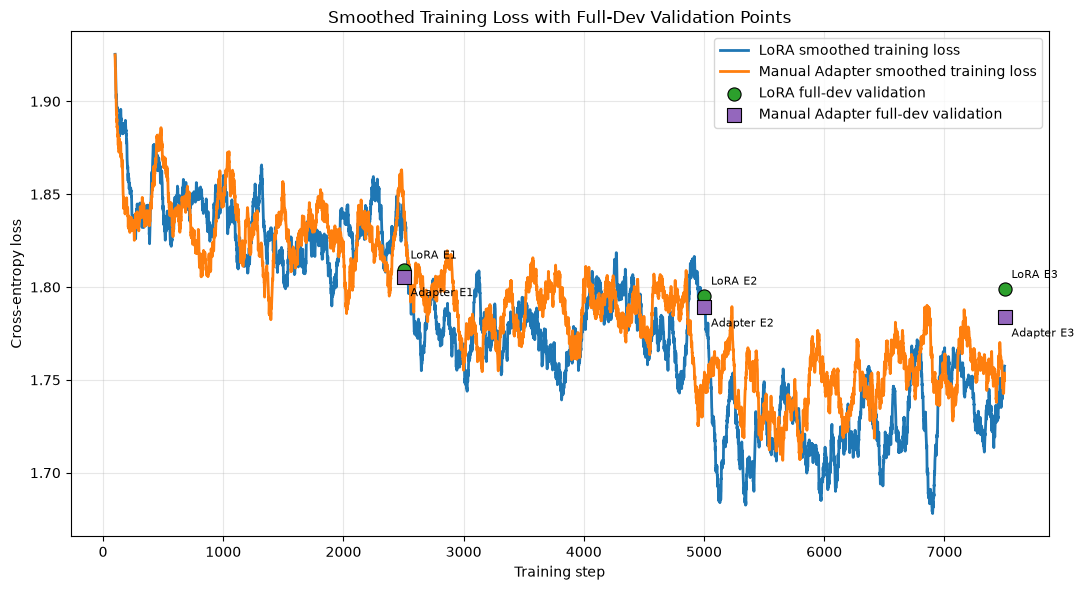

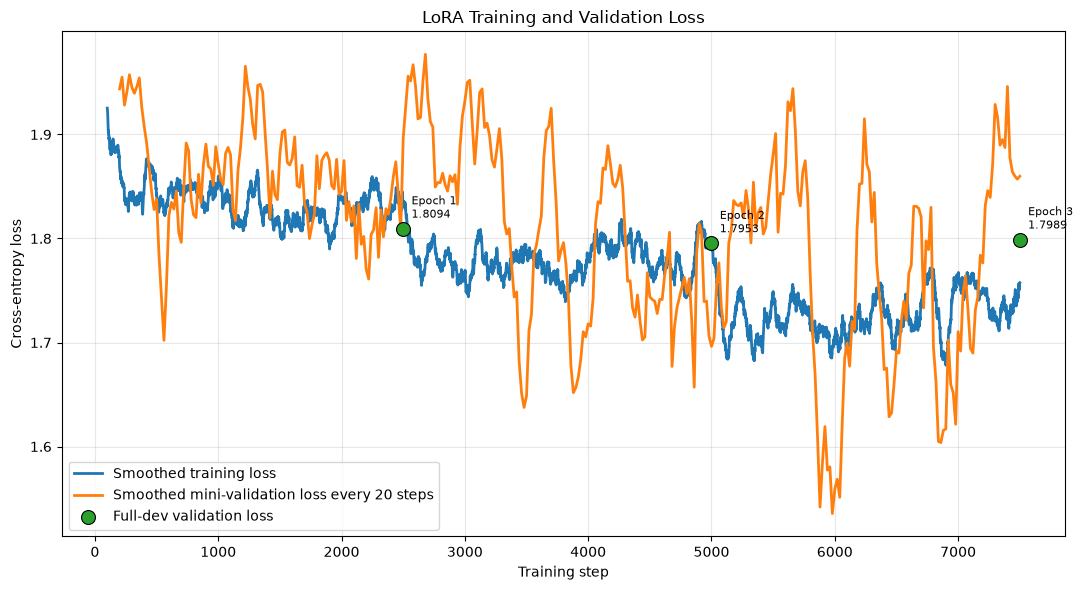

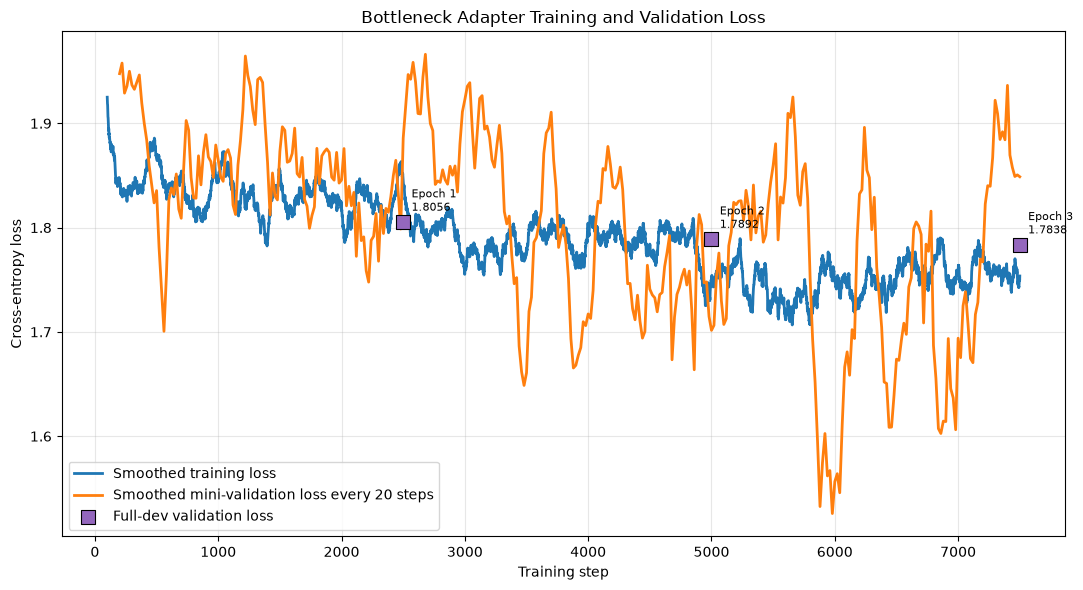

,Epoch,LoRA epoch training loss,LoRA full validation loss,LoRA validation perplexity,Adapter epoch training loss,Adapter full validation loss,Adapter validation perplexity
0,1,1.837921,1.809363,6.106555,1.835557,1.805581,6.083507
1,2,1.778811,1.795328,6.021451,1.786484,1.789198,5.984649
2,3,1.726314,1.798904,6.043023,1.750007,1.783826,5.952586


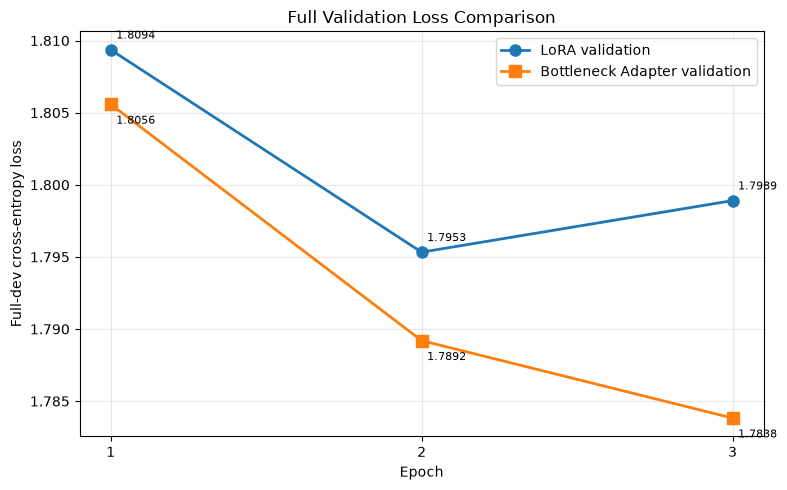

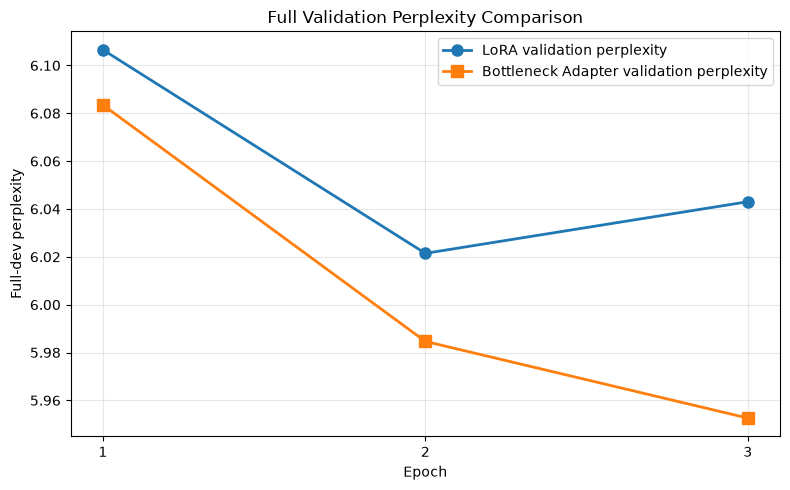

Training loss comparison saved to: /home/jovyan/results/training_loss_curves.png
LoRA train/validation curve saved to: /home/jovyan/results/lora_train_validation_curve.png
Adapter train/validation curve saved to: /home/jovyan/results/adapter_train_validation_curve.png
Validation history saved to: /home/jovyan/results/validation_history.csv
Full validation loss comparison saved to: /home/jovyan/results/validation_loss_comparison.png
Full validation perplexity comparison saved to: /home/jovyan/results/validation_perplexity_comparison.png

LoRA epoch-end validation steps: [2500, 5000, 7500]
Adapter epoch-end validation steps: [2500, 5000, 7500]


In [ ]:
def moving_average(
    values,
    window,
):
    """
    Calculate a moving average while preserving
    the original order of the observations.
    """

    # Convert the input values to a standard Python list
    values = list(values)

    # Ensure the moving-average window is valid
    if window < 1:
        raise ValueError(
            "The moving-average window "
            "must be at least 1."
        )

    # Return an empty list when no values are provided
    if len(values) == 0:
        return []

    # Return the original values when the window is larger than the data
    if len(values) < window:
        return values

    # Convert values to a three-dimensional tensor for average pooling
    value_tensor = torch.tensor(
        values,
        dtype=torch.float32,
    ).view(
        1,
        1,
        -1,
    )

    # Apply one-dimensional average pooling to calculate the moving average
    smoothed = F.avg_pool1d(
        value_tensor,
        kernel_size=window,
        stride=1,
    )

    # Convert the smoothed tensor back to a Python list
    return (
        smoothed
        .flatten()
        .tolist()
    )


def align_steps_with_smoothed_values(
    raw_steps,
    smoothed_values,
):
    """
    Align x-axis positions with the output of
    a valid moving average.
    """

    # Convert the input sequences to standard Python lists
    raw_steps = list(
        raw_steps
    )

    smoothed_values = list(
        smoothed_values
    )

    # Calculate how many initial positions were removed by smoothing
    offset = (
        len(raw_steps)
        - len(smoothed_values)
    )

    # Return the step positions aligned with the smoothed values
    return raw_steps[
        offset:
    ]


def infer_epoch_end_steps(
    step_losses,
    number_of_epochs,
):
    """
    Infer the global training step corresponding
    to the end of each epoch.

    For three epochs, the returned values indicate
    where the three full-dev validation measurements
    should appear on the training-step axis.
    """

    # Get the total number of recorded training steps
    total_steps = len(
        step_losses
    )

    # Ensure the training history contains loss values
    if total_steps == 0:
        raise ValueError(
            "step_losses is empty."
        )

    # Ensure the number of epochs is valid
    if number_of_epochs < 1:
        raise ValueError(
            "number_of_epochs must be at least 1."
        )

    # Estimate the global step corresponding to the end of each epoch
    return [
        round(
            total_steps
            * epoch_number
            / number_of_epochs
        )
        for epoch_number in range(
            1,
            number_of_epochs + 1,
        )
    ]


def validate_epoch_history(
    training_history,
    method_name,
):
    """
    Ensure that one full validation result exists
    for every training epoch.
    """

    # Define the required keys in each training history
    required_keys = [
        "step_losses",
        "epoch_losses",
        "validation_losses",
        "validation_perplexities",
        "validation_curve_steps",
        "validation_curve_losses",
    ]

    # Find any missing history entries
    missing_keys = [
        key
        for key in required_keys
        if key not in training_history
    ]

    # Stop if the training history is incomplete
    if missing_keys:
        raise KeyError(
            f"{method_name} training history "
            f"is missing these keys: "
            f"{missing_keys}"
        )

    # Verify that one training loss exists for each epoch
    if (
        len(
            training_history[
                "epoch_losses"
            ]
        )
        != NUM_EPOCHS
    ):
        raise ValueError(
            f"{method_name} must contain "
            f"{NUM_EPOCHS} epoch losses."
        )

    # Verify that one full validation loss exists for each epoch
    if (
        len(
            training_history[
                "validation_losses"
            ]
        )
        != NUM_EPOCHS
    ):
        raise ValueError(
            f"{method_name} must contain "
            f"{NUM_EPOCHS} full validation losses."
        )

    # Verify that one validation perplexity exists for each epoch
    if (
        len(
            training_history[
                "validation_perplexities"
            ]
        )
        != NUM_EPOCHS
    ):
        raise ValueError(
            f"{method_name} must contain "
            f"{NUM_EPOCHS} validation perplexities."
        )


# ---------------------------------
# Validate histories
# ---------------------------------

# Validate the LoRA training history
validate_epoch_history(
    training_history=lora_training,
    method_name="LoRA",
)

# Validate the adapter training history
validate_epoch_history(
    training_history=adapter_training,
    method_name="Adapter",
)


# ---------------------------------
# LoRA smoothed data
# ---------------------------------

# Create global training-step positions for LoRA
lora_training_steps = list(
    range(
        1,
        len(
            lora_training[
                "step_losses"
            ]
        )
        + 1,
    )
)

# Smooth the LoRA batch-level training losses
lora_smoothed_training_loss = (
    moving_average(
        values=lora_training[
            "step_losses"
        ],
        window=(
            TRAIN_LOSS_SMOOTHING_WINDOW
        ),
    )
)

# Align training-step positions with the smoothed LoRA losses
lora_smoothed_training_steps = (
    align_steps_with_smoothed_values(
        raw_steps=lora_training_steps,
        smoothed_values=(
            lora_smoothed_training_loss
        ),
    )
)

# Smooth the LoRA interval-validation losses
lora_smoothed_validation_loss = (
    moving_average(
        values=lora_training[
            "validation_curve_losses"
        ],
        window=(
            VALIDATION_LOSS_SMOOTHING_WINDOW
        ),
    )
)

# Align validation-step positions with the smoothed validation losses
lora_smoothed_validation_steps = (
    align_steps_with_smoothed_values(
        raw_steps=lora_training[
            "validation_curve_steps"
        ],
        smoothed_values=(
            lora_smoothed_validation_loss
        ),
    )
)

# The three global training steps corresponding
# to the end of LoRA epochs 1, 2, and 3.
lora_epoch_end_steps = (
    infer_epoch_end_steps(
        step_losses=lora_training[
            "step_losses"
        ],
        number_of_epochs=NUM_EPOCHS,
    )
)


# ---------------------------------
# Adapter smoothed data
# ---------------------------------

# Create global training-step positions for the adapter model
adapter_training_steps = list(
    range(
        1,
        len(
            adapter_training[
                "step_losses"
            ]
        )
        + 1,
    )
)

# Smooth the adapter batch-level training losses
adapter_smoothed_training_loss = (
    moving_average(
        values=adapter_training[
            "step_losses"
        ],
        window=(
            TRAIN_LOSS_SMOOTHING_WINDOW
        ),
    )
)

# Align training-step positions with the smoothed adapter losses
adapter_smoothed_training_steps = (
    align_steps_with_smoothed_values(
        raw_steps=adapter_training_steps,
        smoothed_values=(
            adapter_smoothed_training_loss
        ),
    )
)

# Smooth the adapter interval-validation losses
adapter_smoothed_validation_loss = (
    moving_average(
        values=adapter_training[
            "validation_curve_losses"
        ],
        window=(
            VALIDATION_LOSS_SMOOTHING_WINDOW
        ),
    )
)

# Align validation-step positions with the smoothed adapter validation losses
adapter_smoothed_validation_steps = (
    align_steps_with_smoothed_values(
        raw_steps=adapter_training[
            "validation_curve_steps"
        ],
        smoothed_values=(
            adapter_smoothed_validation_loss
        ),
    )
)

# The three global training steps corresponding
# to the end of Adapter epochs 1, 2, and 3.
adapter_epoch_end_steps = (
    infer_epoch_end_steps(
        step_losses=adapter_training[
            "step_losses"
        ],
        number_of_epochs=NUM_EPOCHS,
    )
)


# ---------------------------------
# Training-loss comparison
# with six full-validation points
# ---------------------------------

# Create the combined training-loss comparison figure
plt.figure(
    figsize=(11, 6)
)

# Plot the smoothed LoRA training loss
plt.plot(
    lora_smoothed_training_steps,
    lora_smoothed_training_loss,
    label="LoRA smoothed training loss",
    linewidth=2,
)

# Plot the smoothed adapter training loss
plt.plot(
    adapter_smoothed_training_steps,
    adapter_smoothed_training_loss,
    label=(
        "Manual Adapter smoothed "
        "training loss"
    ),
    linewidth=2,
)

# Three full-dev validation points for LoRA.
plt.scatter(
    lora_epoch_end_steps,
    lora_training[
        "validation_losses"
    ],
    marker="o",
    s=90,
    color="tab:green",
    edgecolors="black",
    linewidths=0.8,
    label="LoRA full-dev validation",
    zorder=5,
)

# Three full-dev validation points for Adapter.
plt.scatter(
    adapter_epoch_end_steps,
    adapter_training[
        "validation_losses"
    ],
    marker="s",
    s=90,
    color="tab:purple",
    edgecolors="black",
    linewidths=0.8,
    label=(
        "Manual Adapter full-dev "
        "validation"
    ),
    zorder=5,
)

# Add the corresponding epoch number
# beside each full-validation point.
for epoch_number, (
    step,
    validation_loss,
) in enumerate(
    zip(
        lora_epoch_end_steps,
        lora_training[
            "validation_losses"
        ],
    ),
    start=1,
):
    plt.annotate(
        f"LoRA E{epoch_number}",
        xy=(
            step,
            validation_loss,
        ),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=8,
    )

# Add epoch labels beside adapter validation points
for epoch_number, (
    step,
    validation_loss,
) in enumerate(
    zip(
        adapter_epoch_end_steps,
        adapter_training[
            "validation_losses"
        ],
    ),
    start=1,
):
    plt.annotate(
        f"Adapter E{epoch_number}",
        xy=(
            step,
            validation_loss,
        ),
        xytext=(5, -14),
        textcoords="offset points",
        fontsize=8,
    )

# Configure the comparison figure labels and title
plt.xlabel(
    "Training step"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "Smoothed Training Loss with "
    "Full-Dev Validation Points"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# Define the output path for the training-loss comparison
loss_curve_path = (
    RESULTS_DIR
    / "training_loss_curves.png"
)

# Save and display the training-loss comparison
plt.savefig(
    loss_curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ---------------------------------
# LoRA continuous train/validation
# with three full-dev points
# ---------------------------------

# Create the LoRA training and validation figure
plt.figure(
    figsize=(11, 6)
)

# Plot the smoothed LoRA training loss
plt.plot(
    lora_smoothed_training_steps,
    lora_smoothed_training_loss,
    label="Smoothed training loss",
    linewidth=2,
)

# Plot the smoothed LoRA mini-validation loss
plt.plot(
    lora_smoothed_validation_steps,
    lora_smoothed_validation_loss,
    label=(
        "Smoothed mini-validation loss "
        f"every {VALIDATION_INTERVAL} steps"
    ),
    linewidth=2,
)

# Plot full-dev LoRA validation points
plt.scatter(
    lora_epoch_end_steps,
    lora_training[
        "validation_losses"
    ],
    marker="o",
    s=100,
    color="tab:green",
    edgecolors="black",
    linewidths=0.8,
    label="Full-dev validation loss",
    zorder=5,
)

# Annotate each LoRA full-validation point
for epoch_number, (
    step,
    validation_loss,
) in enumerate(
    zip(
        lora_epoch_end_steps,
        lora_training[
            "validation_losses"
        ],
    ),
    start=1,
):
    plt.annotate(
        (
            f"Epoch {epoch_number}\n"
            f"{validation_loss:.4f}"
        ),
        xy=(
            step,
            validation_loss,
        ),
        xytext=(6, 8),
        textcoords="offset points",
        fontsize=8,
    )

# Configure the LoRA figure labels and title
plt.xlabel(
    "Training step"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "LoRA Training and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# Define the output path for the LoRA validation curve
lora_validation_curve_path = (
    RESULTS_DIR
    / "lora_train_validation_curve.png"
)

# Save and display the LoRA validation curve
plt.savefig(
    lora_validation_curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ---------------------------------
# Adapter continuous train/validation
# with three full-dev points
# ---------------------------------

# Create the adapter training and validation figure
plt.figure(
    figsize=(11, 6)
)

# Plot the smoothed adapter training loss
plt.plot(
    adapter_smoothed_training_steps,
    adapter_smoothed_training_loss,
    label="Smoothed training loss",
    linewidth=2,
)

# Plot the smoothed adapter mini-validation loss
plt.plot(
    adapter_smoothed_validation_steps,
    adapter_smoothed_validation_loss,
    label=(
        "Smoothed mini-validation loss "
        f"every {VALIDATION_INTERVAL} steps"
    ),
    linewidth=2,
)

# Plot full-dev adapter validation points
plt.scatter(
    adapter_epoch_end_steps,
    adapter_training[
        "validation_losses"
    ],
    marker="s",
    s=100,
    color="tab:purple",
    edgecolors="black",
    linewidths=0.8,
    label="Full-dev validation loss",
    zorder=5,
)

# Annotate each adapter full-validation point
for epoch_number, (
    step,
    validation_loss,
) in enumerate(
    zip(
        adapter_epoch_end_steps,
        adapter_training[
            "validation_losses"
        ],
    ),
    start=1,
):
    plt.annotate(
        (
            f"Epoch {epoch_number}\n"
            f"{validation_loss:.4f}"
        ),
        xy=(
            step,
            validation_loss,
        ),
        xytext=(6, 8),
        textcoords="offset points",
        fontsize=8,
    )

# Configure the adapter figure labels and title
plt.xlabel(
    "Training step"
)

plt.ylabel(
    "Cross-entropy loss"
)

plt.title(
    "Bottleneck Adapter Training "
    "and Validation Loss"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# Define the output path for the adapter validation curve
adapter_validation_curve_path = (
    RESULTS_DIR
    / "adapter_train_validation_curve.png"
)

# Save and display the adapter validation curve
plt.savefig(
    adapter_validation_curve_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ---------------------------------
# Full-dev epoch validation history
# ---------------------------------

# Create the list of epoch numbers
epochs = list(
    range(
        1,
        NUM_EPOCHS + 1,
    )
)

# Build a table containing epoch-level training and validation metrics
validation_history_table = (
    pd.DataFrame(
        {
            "Epoch":
                epochs,

            "LoRA epoch training loss":
                lora_training[
                    "epoch_losses"
                ],

            "LoRA full validation loss":
                lora_training[
                    "validation_losses"
                ],

            "LoRA validation perplexity":
                lora_training[
                    "validation_perplexities"
                ],

            "Adapter epoch training loss":
                adapter_training[
                    "epoch_losses"
                ],

            "Adapter full validation loss":
                adapter_training[
                    "validation_losses"
                ],

            "Adapter validation perplexity":
                adapter_training[
                    "validation_perplexities"
                ],
        }
    )
)

# Display the validation history table
display(
    validation_history_table
)

# Define the CSV output path
validation_history_path = (
    RESULTS_DIR
    / "validation_history.csv"
)

# Save the validation history table
validation_history_table.to_csv(
    validation_history_path,
    index=False,
)


# ---------------------------------
# Full-validation loss comparison
# Three LoRA + three Adapter points
# ---------------------------------

# Create the full-validation loss comparison figure
plt.figure(
    figsize=(8, 5)
)

# Plot LoRA full-validation loss across epochs
plt.plot(
    epochs,
    lora_training[
        "validation_losses"
    ],
    marker="o",
    markersize=8,
    linewidth=2,
    label="LoRA validation",
)

# Plot adapter full-validation loss across epochs
plt.plot(
    epochs,
    adapter_training[
        "validation_losses"
    ],
    marker="s",
    markersize=8,
    linewidth=2,
    label="Bottleneck Adapter validation",
)

# Annotate LoRA validation-loss values
for epoch_number, validation_loss in zip(
    epochs,
    lora_training[
        "validation_losses"
    ],
):
    plt.annotate(
        f"{validation_loss:.4f}",
        xy=(
            epoch_number,
            validation_loss,
        ),
        xytext=(4, 8),
        textcoords="offset points",
        fontsize=8,
    )

# Annotate adapter validation-loss values
for epoch_number, validation_loss in zip(
    epochs,
    adapter_training[
        "validation_losses"
    ],
):
    plt.annotate(
        f"{validation_loss:.4f}",
        xy=(
            epoch_number,
            validation_loss,
        ),
        xytext=(4, -14),
        textcoords="offset points",
        fontsize=8,
    )

# Configure the validation-loss figure labels and title
plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Full-dev cross-entropy loss"
)

plt.title(
    "Full Validation Loss Comparison"
)

plt.xticks(
    epochs
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# Define the output path for the validation-loss comparison
validation_comparison_path = (
    RESULTS_DIR
    / "validation_loss_comparison.png"
)

# Save and display the validation-loss comparison
plt.savefig(
    validation_comparison_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ---------------------------------
# Full-validation perplexity comparison
# ---------------------------------

# Create the full-validation perplexity comparison figure
plt.figure(
    figsize=(8, 5)
)

# Plot LoRA validation perplexity across epochs
plt.plot(
    epochs,
    lora_training[
        "validation_perplexities"
    ],
    marker="o",
    markersize=8,
    linewidth=2,
    label="LoRA validation perplexity",
)

# Plot adapter validation perplexity across epochs
plt.plot(
    epochs,
    adapter_training[
        "validation_perplexities"
    ],
    marker="s",
    markersize=8,
    linewidth=2,
    label=(
        "Bottleneck Adapter "
        "validation perplexity"
    ),
)

# Configure the perplexity figure labels and title
plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Full-dev perplexity"
)

plt.title(
    "Full Validation Perplexity Comparison"
)

plt.xticks(
    epochs
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

# Define the output path for the perplexity comparison
validation_perplexity_path = (
    RESULTS_DIR
    / "validation_perplexity_comparison.png"
)

# Save and display the perplexity comparison
plt.savefig(
    validation_perplexity_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close()


# ---------------------------------
# Saved-output summary
# ---------------------------------

# Display the paths of all saved outputs
print(
    "Training loss comparison saved to:",
    loss_curve_path,
)

print(
    "LoRA train/validation curve "
    "saved to:",
    lora_validation_curve_path,
)

print(
    "Adapter train/validation curve "
    "saved to:",
    adapter_validation_curve_path,
)

print(
    "Validation history saved to:",
    validation_history_path,
)

print(
    "Full validation loss comparison "
    "saved to:",
    validation_comparison_path,
)

print(
    "Full validation perplexity "
    "comparison saved to:",
    validation_perplexity_path,
)

print()

# Display inferred epoch-end steps for both methods
print(
    "LoRA epoch-end validation steps:",
    lora_epoch_end_steps,
)

print(
    "Adapter epoch-end validation steps:",
    adapter_epoch_end_steps,
)

### Compare generated news text

The table contains outputs for all three models and all three prompts.

In [ ]:
# Store generation comparison rows
generation_rows = []

# Add baseline, LoRA, and adapter outputs for each prompt
for index, prompt in enumerate(NEWS_PROMPTS):
    generation_rows.append(
        {
            "Prompt": prompt,
            "Baseline output": baseline_generations[index],
            "LoRA output": lora_generations[index],
            "Adapter output": adapter_generations[index],
        }
    )


# Convert generation results into a table
generation_table = pd.DataFrame(generation_rows)

# Display the generation comparison table
display(generation_table)

# Save the generation comparison table as a CSV file
generation_table.to_csv(
    RESULTS_DIR / "generation_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

,Prompt,Baseline output,LoRA output,Adapter output
0,دیروز در مجلس شورای اسلامی، نمایندگان درباره,دیروز در مجلس شورای اسلامی، نمایندگان درباره ا...,دیروز در مجلس شورای اسلامی، نمایندگان درباره ط...,دیروز در مجلس شورای اسلامی، نمایندگان درباره ط...
1,بر اساس اعلام سازمان هواشناسی، در روزهای آینده,بر اساس اعلام سازمان هواشناسی، در روزهای آینده...,بر اساس اعلام سازمان هواشناسی، در روزهای آینده...,بر اساس اعلام سازمان هواشناسی، در روزهای آینده...
2,وزارت بهداشت امروز در بیانیه‌ای اعلام کرد,وزارت بهداشت امروز در بیانیه‌ای اعلام کرد که ک...,وزارت بهداشت امروز در بیانیه‌ای اعلام کرد که ک...,وزارت بهداشت امروز در بیانیه‌ای اعلام کرد که ک...


### Generate the conceptual and technical analysis

The analysis uses the measured values. The forgetting interpretation is descriptive rather
than a universal statistical threshold.

In [ ]:
def describe_degradation(
    method_name,
    baseline_value,
    tuned_value,
):
    """
    Calculate and interpret the relative change
    in out-of-domain Wikipedia perplexity.
    """

    # Ensure the baseline perplexity is valid
    if baseline_value <= 0:
        raise ValueError(
            "Baseline perplexity must be positive."
        )

    # Calculate the relative perplexity change
    ratio = (
        tuned_value - baseline_value
    ) / baseline_value

    # Convert the relative change to percentage
    percent = 100 * ratio

    # Interpret the degree of out-of-domain degradation
    if ratio <= 0:
        interpretation = (
            "Wikipedia perplexity did not increase. "
            "Therefore, this run does not show "
            "out-of-domain degradation on the "
            "Wikipedia test set."
        )

    elif percent < 5:
        interpretation = (
            "The increase is small and indicates "
            "limited out-of-domain degradation."
        )

    elif percent < 20:
        interpretation = (
            "The increase is noticeable and is "
            "consistent with moderate forgetting."
        )

    else:
        interpretation = (
            "The increase is substantial and is "
            "consistent with strong out-of-domain "
            "forgetting in this experiment."
        )

    # Return the complete degradation analysis
    return (
        f"{method_name} changed Wikipedia perplexity "
        f"from {baseline_value:.4f} to "
        f"{tuned_value:.4f}. The degradation ratio "
        f"is {ratio:.6f} ({percent:.2f}%). "
        f"{interpretation}"
    )


# ---------------------------------
# Catastrophic-forgetting analysis
# ---------------------------------

# Analyze LoRA out-of-domain degradation
lora_forgetting_analysis = (
    describe_degradation(
        method_name="LoRA",
        baseline_value=baseline_wiki[
            "perplexity"
        ],
        tuned_value=lora_wiki[
            "perplexity"
        ],
    )
)

# Analyze manual-adapter out-of-domain degradation
adapter_forgetting_analysis = (
    describe_degradation(
        method_name="Manual adapter",
        baseline_value=baseline_wiki[
            "perplexity"
        ],
        tuned_value=adapter_wiki[
            "perplexity"
        ],
    )
)


# ---------------------------------
# News-learning and preservation
# comparison
# ---------------------------------

# Store news and Wikipedia results for both fine-tuning methods
methods = {
    "LoRA": {
        "news":
            lora_news[
                "perplexity"
            ],

        "wiki":
            lora_wiki[
                "perplexity"
            ],

        "ratio":
            lora_degradation_ratio,
    },

    "Manual adapter": {
        "news":
            adapter_news[
                "perplexity"
            ],

        "wiki":
            adapter_wiki[
                "perplexity"
            ],

        "ratio":
            adapter_degradation_ratio,
    },
}


# Keep only methods that improved news-domain perplexity
methods_that_learned_news = {
    name: values
    for name, values in methods.items()
    if (
        values["news"]
        < baseline_news["perplexity"]
    )
}


# Select the method with the smallest degradation ratio
if methods_that_learned_news:
    preservation_winner = min(
        methods_that_learned_news,
        key=lambda name: (
            methods_that_learned_news[
                name
            ][
                "ratio"
            ]
        ),
    )

    winner_values = (
        methods_that_learned_news[
            preservation_winner
        ]
    )

    # Calculate the winner's relative news perplexity improvement
    winner_news_improvement = (
        baseline_news["perplexity"]
        - winner_values["news"]
    ) / baseline_news["perplexity"]

    # Create the learning-preservation balance analysis
    balance_analysis = (
        f"{preservation_winner} produced the "
        "smallest Wikipedia degradation ratio "
        "among the methods that improved news "
        "perplexity. Its news perplexity improved "
        f"by {100 * winner_news_improvement:.2f}% "
        "relative to the baseline, while its "
        "Wikipedia degradation ratio was "
        f"{100 * winner_values['ratio']:.2f}%. "
        "Therefore, it achieved the better balance "
        "between learning the news domain and "
        "preserving prior general-domain knowledge."
    )

else:
    preservation_winner = None

    # Report unsuccessful domain adaptation
    balance_analysis = (
        "Neither fine-tuning method improved news "
        "perplexity relative to the baseline. "
        "Therefore, the current run does not "
        "demonstrate successful domain adaptation."
    )


# ---------------------------------
# Convergence and overfitting
# analysis
# ---------------------------------

def convergence_text(
    method_name,
    epoch_losses,
    validation_losses,
):
    """
    Analyze convergence using both epoch-level
    training loss and full-dev validation loss.
    """

    # Ensure the training-loss history is available
    if not epoch_losses:
        raise ValueError(
            "The epoch-loss list is empty."
        )

    # Ensure the validation-loss history is available
    if not validation_losses:
        raise ValueError(
            "The validation-loss list is empty."
        )

    # Ensure both histories cover the same number of epochs
    if (
        len(epoch_losses)
        != len(validation_losses)
    ):
        raise ValueError(
            "Training and validation histories "
            "must contain the same number of epochs."
        )

    # Extract first and final training losses
    first_train_loss = (
        epoch_losses[0]
    )

    last_train_loss = (
        epoch_losses[-1]
    )

    # Extract first and final validation losses
    first_validation_loss = (
        validation_losses[0]
    )

    last_validation_loss = (
        validation_losses[-1]
    )

    # Calculate the relative training-loss reduction
    training_relative_drop = (
        (
            first_train_loss
            - last_train_loss
        )
        / abs(first_train_loss)
        if first_train_loss != 0
        else 0.0
    )

    # Calculate the relative validation-loss reduction
    validation_relative_drop = (
        (
            first_validation_loss
            - last_validation_loss
        )
        / abs(first_validation_loss)
        if first_validation_loss != 0
        else 0.0
    )

    # Calculate final-epoch training and validation changes
    if len(epoch_losses) >= 2:
        previous_train_loss = (
            epoch_losses[-2]
        )

        previous_validation_loss = (
            validation_losses[-2]
        )

        final_training_change = (
            (
                previous_train_loss
                - last_train_loss
            )
            / abs(previous_train_loss)
            if previous_train_loss != 0
            else 0.0
        )

        final_validation_change = (
            (
                previous_validation_loss
                - last_validation_loss
            )
            / abs(previous_validation_loss)
            if previous_validation_loss != 0
            else 0.0
        )

    else:
        final_training_change = 0.0
        final_validation_change = 0.0

    # Training loss decreases while validation
    # loss increases noticeably.
    if (
        final_training_change > 0
        and final_validation_change < -0.02
    ):
        convergence_statement = (
            "Training loss continued to decrease, "
            "but full-dev validation loss increased "
            "by more than 2% in the final epoch. "
            "This divergence is evidence of possible "
            "overfitting."
        )

    # Both training and validation are still
    # decreasing noticeably.
    elif (
        final_training_change > 0.02
        and final_validation_change > 0.02
    ):
        convergence_statement = (
            "Both training and full-dev validation "
            "loss were still decreasing by more than "
            "2% in the final epoch. The model was "
            "still improving, so full convergence "
            "is not clearly demonstrated."
        )

    # Both final changes are small.
    elif (
        abs(final_training_change) <= 0.02
        and abs(final_validation_change) <= 0.02
    ):
        convergence_statement = (
            "Both training and full-dev validation "
            "loss changed by at most 2% in the final "
            "epoch. This suggests that training was "
            "approaching a stable plateau."
        )

    # Training loss increases noticeably.
    elif final_training_change < -0.02:
        convergence_statement = (
            "Training loss increased by more than "
            "2% in the final epoch. Therefore, "
            "training did not show a stable "
            "convergence pattern."
        )

    # Validation improves while training changes
    # only slightly.
    elif final_validation_change > 0:
        convergence_statement = (
            "Full-dev validation loss continued to "
            "improve in the final epoch, while the "
            "training-loss change was relatively "
            "small. This does not indicate "
            "overfitting, although additional epochs "
            "might still produce minor improvements."
        )

    else:
        convergence_statement = (
            "The final training and validation "
            "changes do not show a clear divergence, "
            "but they also do not provide strong "
            "evidence of complete convergence."
        )

    # Return the complete convergence analysis
    return (
        f"{method_name} epoch training losses were "
        f"{[round(value, 6) for value in epoch_losses]}. "
        f"The full-dev validation losses were "
        f"{[round(value, 6) for value in validation_losses]}. "
        f"Training loss decreased by "
        f"{100 * training_relative_drop:.2f}% from "
        f"the first to the final epoch, while "
        f"validation loss changed by "
        f"{100 * validation_relative_drop:.2f}% "
        f"over the same period. "
        f"{convergence_statement}"
    )


# Analyze LoRA convergence and possible overfitting
lora_convergence_analysis = (
    convergence_text(
        method_name="LoRA",
        epoch_losses=lora_training[
            "epoch_losses"
        ],
        validation_losses=lora_training[
            "validation_losses"
        ],
    )
)

# Analyze manual-adapter convergence and possible overfitting
adapter_convergence_analysis = (
    convergence_text(
        method_name="Manual adapter",
        epoch_losses=adapter_training[
            "epoch_losses"
        ],
        validation_losses=adapter_training[
            "validation_losses"
        ],
    )
)


# ---------------------------------
# Resource-usage analysis
# ---------------------------------

# Extract pure training times
lora_training_time = (
    lora_training[
        "training_seconds"
    ]
)

adapter_training_time = (
    adapter_training[
        "training_seconds"
    ]
)

# Extract peak allocated VRAM measurements
lora_peak_vram = (
    lora_training[
        "peak_vram_gb"
    ]
)

adapter_peak_vram = (
    adapter_training[
        "peak_vram_gb"
    ]
)

# Calculate adapter-to-LoRA resource differences
training_time_difference = (
    adapter_training_time
    - lora_training_time
)

vram_difference = (
    adapter_peak_vram
    - lora_peak_vram
)

# Calculate the adapter-to-LoRA training-time ratio
if lora_training_time > 0:
    adapter_to_lora_time_ratio = (
        adapter_training_time
        / lora_training_time
    )
else:
    adapter_to_lora_time_ratio = (
        float("nan")
    )

# Create the resource-usage comparison analysis
resource_analysis = (
    f"LoRA used {lora_peak_vram:.3f} GB of "
    "peak allocated VRAM and trained for "
    f"{lora_training_time:.2f} seconds. "
    "The manual adapter used "
    f"{adapter_peak_vram:.3f} GB and trained "
    f"for {adapter_training_time:.2f} seconds. "
    "Relative to LoRA, the manual adapter used "
    f"{vram_difference:+.3f} GB of peak VRAM "
    "and required "
    f"{training_time_difference:+.2f} seconds. "
    "Its training-time ratio relative to LoRA "
    f"was {adapter_to_lora_time_ratio:.3f}. "
    "LoRA inserts low-rank matrices into the "
    "attention projections and benefits from the "
    "optimized PEFT implementation. The manual "
    "adapter adds down-projection, GELU, and "
    "up-projection operations after each MLP and "
    "must retain their intermediate activations "
    "during backpropagation. In the numerically "
    "stable implementation, the adapter branch may "
    "also be evaluated in FP32, which can increase "
    "runtime and memory use relative to FP16 "
    "operations."
)


# ---------------------------------
# Forgetting-mitigation proposal
# ---------------------------------

# Describe a practical method for reducing catastrophic forgetting
mitigation_analysis = (
    "A practical approach for reducing forgetting "
    "is rehearsal or mixed-domain fine-tuning. "
    "A controlled portion of Wikipedia or other "
    "general-domain samples can be mixed with the "
    "Persian news training data. This preserves a "
    "training signal for the model's previous "
    "general-domain knowledge while it learns the "
    "language and style of the news domain. The "
    "mixing ratio should be tuned using the "
    "full-dev validation results to avoid weakening "
    "news-domain adaptation."
)


# ---------------------------------
# Print all analyses
# ---------------------------------

# Print LoRA catastrophic-forgetting analysis
print(
    lora_forgetting_analysis
)

print()

# Print manual-adapter catastrophic-forgetting analysis
print(
    adapter_forgetting_analysis
)

print()

# Print the news-learning and knowledge-preservation comparison
print(
    balance_analysis
)

print()

# Print the resource-usage comparison
print(
    resource_analysis
)

print()

# Print LoRA convergence analysis
print(
    lora_convergence_analysis
)

print()

# Print manual-adapter convergence analysis
print(
    adapter_convergence_analysis
)

print()

# Print the proposed forgetting-mitigation strategy
print(
    mitigation_analysis
)

LoRA changed Wikipedia perplexity from 7.3389 to 9.8037. The degradation ratio is 0.335855 (33.59%). The increase is substantial and is consistent with strong out-of-domain forgetting in this experiment.

Manual adapter changed Wikipedia perplexity from 7.3389 to 8.7992. The degradation ratio is 0.198984 (19.90%). The increase is noticeable and is consistent with moderate forgetting.

Manual adapter produced the smallest Wikipedia degradation ratio among the methods that improved news perplexity. Its news perplexity improved by 22.51% relative to the baseline, while its Wikipedia degradation ratio was 19.90%. Therefore, it achieved the better balance between learning the news domain and preserving prior general-domain knowledge.

LoRA used 15.360 GB of peak allocated VRAM and trained for 14418.93 seconds. The manual adapter used 15.308 GB and trained for 11224.27 seconds. Relative to LoRA, the manual adapter used -0.052 GB of peak VRAM and required -3194.67 seconds. Its training-time r

### Manual qualitative review table

After reading the generated outputs, replace the placeholder text below with short
observations about:

- News tone and fluency
- Relevance to the prompt
- Unsupported factual claims
- Names, numbers, dates, or quotations that appear without evidence
- Repetition or incoherence

In [ ]:
# Print each prompt and its generated outputs for all models
for index, prompt in enumerate(
    NEWS_PROMPTS
):
    # Print a separator between prompt sections
    print("=" * 80)

    # Print the prompt number and original prompt text
    print(f"Prompt {index + 1}:")
    print(prompt)

    # Print the baseline model output
    print("\nBaseline:")
    print(baseline_generations[index])

    # Print the LoRA model output
    print("\nLoRA:")
    print(lora_generations[index])

    # Print the manual adapter model output
    print("\nManual adapter:")
    print(adapter_generations[index])

    # Add an empty line after each prompt section
    print()

Prompt 1:
دیروز در مجلس شورای اسلامی، نمایندگان درباره

Baseline:
دیروز در مجلس شورای اسلامی، نمایندگان درباره طرحی به نام «اصلاح قانون انتخابات» بحث و تبادل نظر کردند.

در این جلسه، نمایندگان با 184 رای موافق، 72 رای مخالف و 10 رای ممتنع از مجموع 263 نماینده حاضر در صحن علنی، طرح اصلاح قانون انتخابات را تصویب کردند.

این طرح که توسط کمیسیون اصل نود (90) قانون اساسی تهیه شده بود، شامل 15 ماده است که مهمترین آنها عبارتند از:

- حذف شرط سنی برای کاندیداتوری در انتخابات ریاست

LoRA:
دیروز در مجلس شورای اسلامی، نمایندگان درباره لایحه بودجه سال ۹۹ اظهار نظر کردند.

در این جلسه، نمایندگان به بررسی بخش‌های مختلف لایحه بودجه پرداختند و برخی از آنها خواستار اصلاح برخی از بندها شدند. [n] در ادامه این جلسه، نمایندگان با طرح سوالی از وزیر اقتصاد، به عملکرد وزارت امور اقتصادی و دارایی در حوزه مالیاتی و همچنین نحوه اجرای قانون مالیات بر ارزش افزوده پرداختند. [n] در پایان این جلسه، نمایندگان با رای گیری، موافقت خود را با لایحه بودجه سال ۹۹ اعلام کردند.

Manual adapter:
دیروز در مجلس شورای اسلامی، نما